# Where Llama goes when an algorithm is banned

**Demo notebook for experiment 15** of the "prompt bans substitute, not just subtract" project.

When you tell an instruction-tuned model *"Do not use a full sort for this task"*, it has to leave its default (its "average" answer) and write something else. Does it land somewhere **predictable**, and which ban-free signal predicts *where*? This experiment asks that of **Llama-3.1-8B-Instruct** (bf16, revision `0e9e39f`) on the frozen 12-task exp11 coding bench (k-th smallest, substring search, two-sum, find-duplicate, connected components, LIS, …). Each task has a catalogue of 3–6 algorithms ("modes"), and every generated program is labelled with the mode it implements.

Four forecast **families** were built from ban-free data only, and sha256 hash-chained into `commitments.log` **before any ban prompt was ever rendered**:

| family | ban-free evidence | forecast |
|---|---|---|
| **SUBTRACT** | the banned algorithm X is *physically removed*: its signature n-grams are vetoed during decoding (truncate-and-redraw in vLLM; one-shot, persistent and iterated rounds) | landing of the last persistent veto round with ≥ 20 non-banned attempts |
| **LADDER** | generic "do something else" pushes: a nonce ban (*"the Zorblax method"*), a novelty instruction, and 3 random residual-stream directions of matched norm added at layers 11–21 during prefill | pooled non-default landing of the pushes |
| **ASSOCIATE** | Llama's own answer to "what would you use instead of X?" | mass transfer: X's share moves onto the associate |
| **PROXIMITY** | the surviving mode whose programs are closest to X's (Zhang–Shasha tree-edit distance on identifier-normalised ASTs) | mass transfer onto the nearest survivor |

Then 1,800 bans were sampled: 18 events × 5 ban templates (W1–W5) × 20 samples, where 12 *modal* events ban the task's default D and 6 *present-minor* events ban a minority mode. The **frozen C1 rule** scores each family by the smoothed log score of where the model actually landed.

**Published result (within Llama, pre-pooling).** 13 events pass the gate and 11 of those are disagreeing. There are only 2 wins (SUBTRACT on T05, ASSOCIATE on T03 `heapify_pop`), so no family advances and the branch is **NO FAMILY ADVANCES (aimed, unresolved)**. SUBTRACT and LADDER beat PROXIMITY (exact Wilcoxon p = 0.0029 / 0.0020, Holm-rejected) but neither separates from ASSOCIATE. LADDER and ASSOCIATE call the top-1 landing on 7/13 gated events (binomial p = 0.033 against chance ≈ 0.27). For five of the 12 modal events the ban barely works: the banned default is still written in 70–96 % of the attempts (avoidance 0.04–0.30).

**What runs here.** `method.py` is a 13-stage pipeline, one sub-command per stage. The generation and labelling stages need an NVIDIA GPU with vLLM, the gated Llama weights, an OpenRouter judge and the frozen bench code (about 1.8 GPU-hours), so their original code is included for reading but is not called. The two CPU stages are re-run from the frozen data in `mini_demo_data.json`:

* **Step F (`commit`)**: rebuild the four forecasts of every event from the ban-free generations with the original `build_event`, and check them against the hash-chained commitment.
* **Step H (`analyse`)**: score the 1,800 labelled ban samples with the frozen C1 rule (gate, log scores, wins, Wilcoxon + Holm, top-1 binomial, branch), run the sensitivities and descriptive analyses, and compare everything with the published numbers.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (method.py logs with it)
_pip('loguru==0.7.3')

# numpy, scipy, pandas, matplotlib — pre-installed on Colab, install locally only (at Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# ---- method.py import block (original) ----
import argparse
import sys
import time
from pathlib import Path

# sys.path.insert(0, str(Path(__file__).resolve().parent))  # notebook: no __file__, and no src/ package to import

from loguru import logger  # noqa: E402

# from src.ws import DATA as DATA_DIR, RESULTS, set_ram_limit, setup_logging, write_json  # noqa: E402
# notebook: src/ws.py only maps the workspace paths and JSON helpers; every input here comes from mini_demo_data.json

# ---- imports of the src/ modules inlined below (scoring.py, forecasts.py, stats_util.py, analysis.py, commit.py) ----
import collections
import hashlib
import json
import math
from collections import Counter, defaultdict
from typing import Any

import numpy as np

# ---- notebook additions: namespaces standing in for the imported src/ modules, tables and plots ----
import types

import matplotlib.pyplot as plt
import pandas as pd

logger.remove()  # as in src/ws.py setup_logging(): INFO lines to stdout (no log file in the notebook)
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")

1

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-3/experiment-15/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
META = data["metadata"]                     # frozen inputs of Steps F and H (see scripts/build_mini_demo_data.py)
EXAMPLES = data["datasets"][0]["examples"]  # dataset llama_bench_events: one example per C1 event
print(f"{data['datasets'][0]['dataset']}: {len(EXAMPLES)} events, "
      f"{sum(len(ex['ban_rows']) for ex in EXAMPLES)} labelled ban samples")
ex0 = EXAMPLES[0]
print(f"\nexample event {ex0['event_id']}:\n{ex0['input'][:640]} ...")
print(f"\nmodal ban landing: {ex0['output']}   attempted labels under the ban: {ex0['metadata_landing_counts']}")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
llama_bench_events: 18 events, 1800 labelled ban samples

example event T03|modal|full_sort:
Event T03|modal|full_sort (modal): Llama-3.1-8B-Instruct is told not to use a full sort on task T03; default D = full_sort. Survivors: size_k_heap, heapify_pop, quickselect, median_of_medians, counting_sort. W1 ban prompt:
Do not use a full sort for this task.

Task: write a Python function solve(nums, k) that returns the k-th smallest value in nums. The argument nums is a list of integers with 1 <= len(nums) <= 2000, and every value lies between -10000 and 10000 inclusive; values may repeat. The argument k is an integer with 1 <= k <= len(nums), counted from 1, so k = 1 asks for the minimum and k = len(nums) for the maximum. Repeat ...

modal ban landing: quickselect   attempted labels under the ban: {'quickselect': 43, 'heapify_pop': 9, 'size_k_heap': 27, 'other': 8, 'full_sort': 5}


## Configuration

Every size knob of the two CPU stages. Smaller values give a valid but smaller run, which will not reproduce the published numbers. For example, with fewer than 20 non-banned attempts per event no event can pass the gate, and with fewer than 10 gated disagreeing events the Wilcoxon tests are not run. The comparison cell near the end reports whether the run matches the published `method_out.json`.

In [5]:
# Demo scale: the original values of the full run (the notebook was tested from 1 / 1 / 10 / 10 upward; see README.md)
N_EVENTS = 18        # C1 events scored, in predictions/events.json order (original: 18 = 12 modal + 6 present-minor)
N_PER_TEMPLATE = 20  # ban samples used per event and ban template W1-W5 (original: 20, i.e. 100 samples per event)
N_BOOT = 2000        # task-cluster bootstrap resamples per Wilcoxon pair in aggregate() (original: 2000)
N_NULL = 1000        # template-bootstrap draws of the JSD null in the C2b descriptive analysis (original: 1000)

## The pipeline in `method.py`

`method.py` runs one sub-command per stage (Steps A–H of the pre-registered plan), in this order:

| sub-command | step | what it does | needs |
|---|---|---|---|
| `setup` | A | provenance, sha256 checks of the copied inputs, model record, X0 freeze | `inputs/` |
| `gen1` | B | vLLM session 1: sampler test (T2), ban-free generations B1–B5 | GPU |
| `label` | C | label every program with the mode it implements (bench AST + runtime labellers, LLM judge on disagreements) | bench code, OpenRouter |
| `freeze` | C4/C5 | default D per task, present-minor events → `predictions/events.json` | labels |
| `assoc` | C6/C7 | map association answers onto modes; forced-mode summary | OpenRouter |
| `hf` | E1 | ban-displacement norms (prompt-only HF forward), random directions, hook tests | GPU |
| `push` | E3 | random-direction pushes at the spec positions of layers 11–21 (prefill only) | GPU |
| `veto` | D1–D3 | signature n-grams of X; exact one-shot / persistent / iterated vetoes | GPU |
| `proximity` | – | Zhang–Shasha AST-distance nominations | programs |
| `commit` | F | build the four forecasts, hash-chain them, grep audit | **runs here** |
| `ban` | G | sample 5 templates × 20 bans per event, after verifying the commitment | GPU |
| `analyse` | H | frozen C1 scoring, sensitivities, descriptive analyses, `method_out.json` | **runs here** |
| `screen` | B6/D4/H6 | descriptive path-task screen against exp10's landings | GPU |

The original code of every stage follows in file order. A stage function is **defined but not called** when it needs the GPU, the bench code or the full artifact workspace (`src/`, `inputs/`, `data/`). Each of those cells is followed by the runnable re-creation where one is possible.

### Steps A–C: provenance, ban-free generations, labels, the frozen default (reference only)

* `setup` (A). Checks the sha256 of every input copied from earlier experiments, records the model snapshot (4 safetensors shards identical to exp10) and freezes X0.
* `gen1` (B, vLLM session 1). Runs the sampler test T2 (temperature 1.0, top-p 1.0, an explicit seed per request), then the ban-free generations:
  * **B1** neutral baselines and **B4** veto-free twins: 50 each per task (5 templates × 10 samples), on *twin* prompts padded with filler until their length and task-spec token positions equal those of the ban prompts.
  * **B3** forced programs, one per named mode (for PROXIMITY).
  * **B2** association answers (for ASSOCIATE).
  * **B5** nonce ban and novelty instruction (for LADDER).
* `label` (C). Extracts every program, runs it against the task's tests and labels it with the mode it implements, using the bench's AST and runtime labellers. An OpenRouter LLM judge settles disagreements; the whole run's judge spend was USD 0.48.
* `freeze` (C4/C5). Fixes three things per task:
  * the decision set: the 50 bf16 B1 samples pooled with the 50 FP8 pilot samples of exp11, since the two were homogeneous on every task; the bf16-only B1 + B4 set is kept as a sensitivity;
  * the default D: the modal correct label, or the modal attempted label when there are too few correct programs;
  * the present-minor events.

  It writes them to `predictions/events.json`.

In [6]:
# method.py, Steps A-C (reference only: needs vLLM on a GPU, the frozen bench labellers and OpenRouter)
def cmd_setup(args) -> None:
    from src.setup_inputs import run
    run()


def _sampler_test(llm) -> dict:
    """T2: explicit params logged; T=1.0 vs a deliberate T=0.6 run at identical seeds must differ."""
    from src import prompts_llama as P
    from src.engine_vllm import effective_params, generate, sampling
    from src.jobs import x0

    p = P.p_twin("T04", x0()["T04"], 1, 0)
    reqs = [{"prompt_ids": p["ids"], "max_tokens": 48, "seed": 1000 + i} for i in range(20)]
    a = generate(llm, reqs)
    b = generate(llm, reqs)
    from vllm import SamplingParams
    from vllm.inputs import TokensPrompt
    sps = [SamplingParams(n=1, temperature=0.6, top_p=0.9, top_k=-1, max_tokens=48, seed=1000 + i,
                          stop_token_ids=[128001, 128008, 128009]) for i in range(20)]
    c = llm.generate([TokensPrompt(prompt_token_ids=p["ids"]) for _ in range(20)], sps, use_tqdm=False)
    c_ids = [list(o.outputs[0].token_ids) for o in c]
    same_rerun = sum(x["out_ids"] == y["out_ids"] for x, y in zip(a, b))
    same_t06 = sum(x["out_ids"] == y for x, y in zip(a, c_ids))
    eff = effective_params(sampling(1024, 1))
    res = {"effective_params": eff, "n": 20, "identical_on_rerun_same_seed": same_rerun,
           "identical_T1_vs_T0.6_same_seed": same_t06,
           "passed": eff["temperature"] == 1.0 and eff["top_p"] == 1.0 and eff["top_k"] in (-1, 0) and same_t06 < 20}
    write_json(RESULTS / "tests_sampler.json", res)
    logger.info(f"T2 sampler test: {res}")
    return res


def cmd_gen1(args) -> None:
    from src.engine_vllm import make_llm
    from src import jobs as J

    llm = make_llm(prefix_caching=True)
    try:
        cc = llm.llm_engine.vllm_config.cache_config
        kv = {"num_gpu_blocks": cc.num_gpu_blocks, "block_size": cc.block_size,
              "kv_tokens": (cc.num_gpu_blocks or 0) * cc.block_size}
    except AttributeError as e:
        kv = {"error": str(e)}
    write_json(RESULTS / "kv_cache_session1.json", kv)
    logger.info(f"KV cache: {kv}")
    _sampler_test(llm)
    only = set(args.phases.split(",")) if args.phases else None
    plan = [("B1", lambda: J.reqs_twin_family("B1", "neutral_baseline")),
            ("B4", lambda: J.reqs_twin_family("B4", "vetofree")),
            ("B3r1", lambda: J.reqs_forced(list(range(10)), 2, "r1")),
            ("B2", lambda: J.reqs_association()),
            ("B5", lambda: J.reqs_nonce_novelty())]
    for name, fn in plan:
        if only and name not in only:
            continue
        t0 = time.time()
        J.run_staged(llm, fn(), name)
        logger.info(f"{name} done in {time.time() - t0:.0f}s")


def cmd_label(args) -> None:
    """Label every raw generation (and the exp11 FP8 pilot) not yet labelled; then combine with the judge."""
    from src import label as L
    from src.jobs import raw_rows

    phases = set(args.phases.split(",")) if args.phases else None
    rows = L.pilot_rows() + raw_rows()
    rows = [r for r in rows if phases is None or r["phase"] in phases]
    if args.limit:
        rows = rows[: args.limit]
    L.label_rows(rows, workers=args.workers)
    if not args.no_judge:
        raw_by_id = {r["row_id"]: r for r in L.pilot_rows() + raw_rows()}
        L.combine(raw_by_id)
        logger.info(f"judge spend total ${L.judge_spend():.4f}")


def _labels_now(judge: bool = True) -> list[dict]:
    from src import label as L
    from src.jobs import raw_rows

    raw_by_id = {r["row_id"]: r for r in L.pilot_rows() + raw_rows()}
    return L.combine(raw_by_id, judge_ok=judge)


def cmd_freeze(args) -> None:
    """C4/C5: decision set, D, present-minor events (needs labels of pilot, B1, B4); association later (commit)."""
    from src import freeze as F

    labels = _labels_now()
    F.run(labels, assoc=[])

### Steps E1/E3: LADDER's matched-norm random pushes (reference only)

`hf` runs a prompt-only HF forward pass and measures how far the ban sentence moves the residual stream at the task-spec token positions of decoder layers 11–21: n_{l,i} = mean over templates of ‖h(ban_w(D)) − h(twin_w(D))‖. `push` then adds random unit directions scaled to exactly those norms at the same positions, during prefill only, with vLLM forward hooks (3 random seeds). The result is a **ban-sized push that carries no information about *which* algorithm is banned**. Together with the nonce ban and the novelty instruction from B5, it gives **LADDER**'s evidence. The hook test T4 checks that a zero-norm push is a no-op (10/10 identical) and that the added norm matches the target (ratio 0.9998).

In [7]:
# method.py, Steps E1-E3 (reference only: needs the Llama weights, HF transformers and vLLM on a GPU)
def cmd_hf(args) -> None:
    """E1/E2 + T4 (HF part): ban-displacement norms for D (prompt-only), random directions, hook tests."""
    from src.engine_hf import run
    from src.ws import PRED, read_json

    ev = read_json(PRED / "events.json")
    D = {t: v["D"] for t, v in ev["tasks"].items()}
    x0 = read_json(PRED / "x0.json")["x0"]
    run(D, x0)


def cmd_push(args) -> None:
    """E3: random-direction pushes at the spec positions of layers 11-21 (prefill only), X0-family twin prompts."""
    import numpy as np
    import torch
    from src import jobs as J
    from src import prompts_llama as P
    from src.engine_hf import directions
    from src.engine_vllm import PushHooks, generate, make_llm
    from src.ws import PRED, PUSH_LAYERS, RANDDIR_SEEDS, read_json, request_seed

    norms = read_json(RESULTS / "ban_norms.json")
    x0 = read_json(PRED / "x0.json")["x0"]
    seeds = RANDDIR_SEEDS[: (args.limit or len(RANDDIR_SEEDS))]
    llm = make_llm(prefix_caching=False)
    # C7 forced round 2 (hooks not yet installed): modes with < 5 correct-and-adherent round-1 programs
    fs = read_json(RESULTS / "forced_summary.json")
    need: dict = {}
    for v in fs.values():
        if v["needs_round2"]:
            need.setdefault(v["task"], []).append(v["mode"])
    if need and not args.phases:
        r2 = J.reqs_forced([-1], 10, "r2", modes_only=need) + J.reqs_forced(list(range(10)), 1, "r2", modes_only=need,
                                                                               start=2)
        J.run_staged(llm, r2, "B3r2")
    hooks = PushHooks(llm, PUSH_LAYERS)
    tasks = list(norms["tasks"].keys())

    def registry(scale: float) -> dict:
        reg = {}
        for t in tasks:
            nt = torch.tensor(np.array(norms["tasks"][t]["norms"]) * scale, dtype=torch.float32, device="cuda")
            for w in range(1, 6):
                for h in (0, 1):
                    p = P.p_twin(t, x0[t], w, h)
                    S = p["spec_end"] - p["spec_start"] + 1
                    assert S == nt.shape[1], (t, w, h, S, nt.shape)
                    reg[tuple(p["ids"])] = {"spec_start": p["spec_start"], "norms": nt, "norms_dev": nt, "task": t}
        return reg

    # T4 (vLLM part): zero-norm direction == hook-free run at the same seeds; perturbed-token accounting
    p = P.p_twin("T04", x0["T04"], 1, 0)
    reqs = [{"prompt_ids": p["ids"], "max_tokens": 64, "seed": 777 + i} for i in range(10)]
    hooks.set({}, None)
    a = generate(llm, reqs)
    hooks.set(registry(0.0), directions(seeds[0]).to("cuda"))
    hooks.stats.update(steps=0, perturbed_tokens=0)
    b = generate(llm, reqs)
    S = p["spec_end"] - p["spec_start"] + 1
    t4 = {"zero_norm_identical": sum(x["out_ids"] == y["out_ids"] for x, y in zip(a, b)), "n": 10,
          "perturbed_tokens": hooks.stats["perturbed_tokens"], "expected_perturbed_tokens": 10 * S * 1}
    hooks.set(registry(1.0), directions(seeds[0]).to("cuda"))
    hooks.stats.update(steps=0, perturbed_tokens=0, added_norm_sum=0.0, target_norm_sum=0.0)
    c = generate(llm, reqs)
    t4["perturbed_tokens_real"] = hooks.stats["perturbed_tokens"]
    t4["added_over_target_l21"] = hooks.stats["added_norm_sum"] / max(hooks.stats["target_norm_sum"], 1e-9)
    t4["differs_from_unperturbed"] = sum(x["out_ids"] != y["out_ids"] for x, y in zip(a, c))
    t4["passed"] = (t4["zero_norm_identical"] >= 9 and t4["perturbed_tokens"] == t4["expected_perturbed_tokens"]
                    and abs(t4["added_over_target_l21"] - 1) < 0.02)
    write_json(RESULTS / "tests_hooks_vllm.json", t4)
    logger.info(f"T4 vLLM hook test: {t4}")
    for k, sd in enumerate(seeds):
        hooks.set(registry(1.0), directions(sd).to("cuda"))
        hooks.stats.update(steps=0, perturbed_tokens=0, added_norm_sum=0.0, target_norm_sum=0.0)
        reqs = []
        for t in tasks:
            for w in range(1, 6):
                for s in range(10):
                    h = 0 if s < 5 else 1
                    pp = P.p_twin(t, x0[t], w, h)
                    reqs.append(J._req(pp, phase="E3", condition=f"randdir:s{k}", task=t, template=w, sample_id=s,
                                       h=h, mode=x0[t], extra={"randdir_seed": sd}))
        J.run_staged(llm, reqs, f"E3_s{k}")
        st = dict(hooks.stats)
        st["added_over_target_l21"] = st["added_norm_sum"] / max(st["target_norm_sum"], 1e-9)
        logger.info(f"push s{k} hook stats: {st}")
        allst = read_json(RESULTS / "push_hook_stats.json") if (RESULTS / "push_hook_stats.json").exists() else {}
        allst[f"s{k}"] = st
        write_json(RESULTS / "push_hook_stats.json", allst)
    hooks.remove()

### Steps C6/C7, D and PROXIMITY: association map, exact vetoes, AST nominations (reference only)

* `forced_summary` / `assoc` (C6/C7). Adherence of the *forced* programs per (task, mode), where the model is asked to implement one named mode; a second forced round runs if fewer than 5 are correct and adherent. `assoc` also maps the free-text association answers ("instead of X I would use …") onto catalogue modes, using a lexicon and the judge for unmapped answers. This is **ASSOCIATE**'s evidence.
* `veto` (D1–D3). Picks signature n-grams of X (token sequences present in X's programs and rare elsewhere) and regenerates with them **vetoed**: whenever the model emits one, the continuation is truncated and redrawn without it, in one-shot, persistent and iterated rounds. X is removed *without telling the model anything*. This is **SUBTRACT**'s evidence.
* `proximity`. For each event, ranks the survivors by Zhang–Shasha tree-edit distance between their forced programs and the model's own X programs (identifier-normalised ASTs). The nearest survivor is **PROXIMITY**'s nominee.

In [8]:
# method.py, Steps C6/C7, D1-D3 and PROXIMITY (reference only: needs vLLM on a GPU, the bench code and OpenRouter)
def forced_summary(labels: list[dict]) -> dict:
    """C7: adherence and correctness per mode from forced rows (label == requested mode = adherent)."""
    import collections
    from src import prompts_llama as P
    from src.ws import FROZEN_TASKS

    out = {}
    for t in FROZEN_TASKS:
        for m in P.modes(t):
            rs = [r for r in labels if r["task"] == t and (r.get("condition") or "").startswith(f"forced:{m}:")]
            att = [r for r in rs if r["label"] != "invalid"]
            adh = [r for r in att if r["label"] == m]
            ca = [r for r in adh if r.get("passed")]
            scr = [r for r in ca if (r.get("scrub") or {}).get("verified")]
            out[f"{t}|{m}"] = {"task": t, "mode": m, "n": len(rs), "n_valid": len(att), "n_adherent": len(adh),
                               "n_correct_adherent": len(ca), "n_correct_adherent_scrub_verified": len(scr),
                               "adherence": len(adh) / max(len(att), 1),
                               "label_counts": dict(collections.Counter(r["label"] for r in rs)),
                               "can_write": len(ca) >= 1, "needs_round2": len(ca) < 5,
                               "rounds": sorted({r["phase"] for r in rs})}
    write_json(RESULTS / "forced_summary.json", out)
    return out


def cmd_assoc(args) -> None:
    """C6: map association answers (lexicon, judge for unmapped) + forced summary (C7 trigger)."""
    from src import label as L
    from src.jobs import raw_rows

    labels = _labels_now()
    fs = forced_summary(labels)
    logger.info(f"forced: {sum(1 for v in fs.values() if v['needs_round2'])} modes need round 2: "
                f"{[k for k, v in fs.items() if v['needs_round2']]}")
    rows = raw_rows({"B2"})
    if rows:
        am = L.map_association(rows)
        import collections
        logger.info(f"association: {len(am)} answers; categories {dict(collections.Counter(a['category'] for a in am))}")
    logger.info(f"judge spend total ${L.judge_spend():.4f}")


def cmd_veto(args) -> None:
    """D1-D3: n-grams and exact vetoes (vLLM session 3a, prefix caching on), labelled between rounds."""
    from src.engine_vllm import make_llm
    from src import veto_job as V

    _labels_now()  # combined labels incl. forced round 2 before n-gram selection
    llm = make_llm(prefix_caching=True)
    V.run(llm, args)


def cmd_proximity(args) -> None:
    """PROXIMITY nominations (ZS on identifier-normalised ASTs; canon token Levenshtein sensitivity)."""
    import collections
    from src import label as L
    from src import prompts_llama as P
    from src.jobs import raw_rows
    from src.ngrams import reference_code
    from src.proximity import nominate
    from src.ws import PRED, read_json, read_jsonl

    ev = read_json(PRED / "events.json")
    dec = read_json(RESULTS / "decision_sets.json")
    labels = read_jsonl(L.LABELS)
    lab_by = {r["row_id"]: r for r in labels}
    raw_by = {r["row_id"]: r for r in L.pilot_rows() + raw_rows()}
    forced = collections.defaultdict(list)
    for r in labels:
        c = r.get("condition") or ""
        if c.startswith("forced:") and r["label"] == c.split(":")[1]:
            code, _ = L.extract(raw_by[r["row_id"]]["text"])
            if code:
                forced[(r["task"], r["label"])].append(code)
    jobs = []
    for e in ev["events"]:
        t, X = e["task"], e["banned"]
        xs = []
        for rid in dec[t]["decision_row_ids"]:
            if lab_by.get(rid, {}).get("label") == X:
                code, _ = L.extract(raw_by[rid]["text"])
                if code:
                    xs.append(code)
        surv, src = {}, {}
        for j in P.modes(t):
            if j == X:
                continue
            js = forced.get((t, j), [])
            if not js:
                rc = reference_code(t, j)
                js = [rc] if rc else []
                src[j] = "bench_reference(no adherent forced program)"
            else:
                src[j] = f"forced_adherent(n={len(js)})"
            surv[j] = js
        jobs.append({"event_id": e["event_id"], "X": X, "xs": xs, "survivors": surv, "sources": src})
    res = nominate(jobs, workers=args.workers)
    write_json(PRED / "proximity.json", res)
    logger.info(f"proximity: k_used={res['k_used']} agreement={res['nomination_agreement']:.2f} "
                f"{ {k: v['nominee_zs'] for k, v in res['events'].items()} }")

## Step F: commit the forecasts before any ban is sampled

`_forecast_ctx()` gathers everything the forecasts read: decision-set labels, push labels, association targets, proximity nominees and veto rounds. `cmd_commit` then builds one forecast per event with `build_event` and writes `predictions/forecasts.json`. It hash-chains that file, together with `scoring.py` and `forecasts.py` themselves, into `commitments.log`, and runs a grep audit confirming that no ban prompt had been rendered yet (0 of 10,328 rows). The original code below reads the workspace files, so it is reference only. The cells after it re-run its core on the data.

In [9]:
# method.py, Step F (reference only: reads and writes the workspace files predictions/, data/, results/)
def _forecast_ctx() -> dict:
    """Everything the forecasts read: decision-set labels, veto rounds, push labels, association, proximity."""
    import collections
    from src import label as L
    from src.forecasts import push_label_index
    from src.freeze import associate_targets
    from src.jobs import raw_rows
    from src.ws import PRED, read_json, read_jsonl

    labels = read_jsonl(L.LABELS)
    lab_by = {r["row_id"]: r for r in labels}
    dec = read_json(RESULTS / "decision_sets.json")
    ev = read_json(PRED / "events.json")
    ctx = {"decision_labels": {t: [lab_by[r]["label"] for r in v["decision_row_ids"] if r in lab_by]
                               for t, v in dec.items()},
           "push_labels": push_label_index(labels)}
    import os
    atf = PRED / "association_targets.json"
    if atf.exists() and not os.access(atf, os.W_OK):  # committed (read-only): never recompute after the commit
        at = read_json(atf)
    else:
        at = associate_targets(read_jsonl(L.ASSOC))
        write_json(atf, at)
    ctx["assoc_targets"] = at
    prox = read_json(PRED / "proximity.json") if (PRED / "proximity.json").exists() else {"events": {}}
    ctx["proximity"] = prox["events"]
    vs = read_json(DATA_DIR / "veto_summary.json") if (DATA_DIR / "veto_summary.json").exists() else {}
    raw_v = [r for r in raw_rows({"D2", "D3"})]
    veto = {}
    for e in ev["events"]:
        eid, X = e["event_id"], e["banned"]
        ent = {"ngrams": vs.get(eid, {}).get("ngrams"), "undefined_reason": vs.get(eid, {}).get("undefined_reason")}
        rr = [r for r in raw_v if r["event_id"] == eid]
        p1 = {}
        if e["event_type"] == "present_minor":
            p1 = {r: lab_by[r]["label"] for r in dec[e["task"]]["decision_row_ids"]}  # placeholder, replaced below
            p1 = {}
            for r in raw_rows({"B1", "B4"}):
                if r["task"] == e["task"] and r["row_id"] in lab_by:
                    p1[r["row_id"]] = lab_by[r["row_id"]]["label"]
        rounds = sorted({r["round"] for r in rr if r["arm"] == "persistent"})
        pr = []
        for k in rounds:
            sel = [r for r in rr if r["arm"] == "persistent" and r["round"] == k]
            labs = [lab_by.get(r["row_id"], {}).get("label") for r in sel]
            wts = [r["weight"] for r in sel]
            hit = [bool(r["hit"]) for r in sel]
            if e["event_type"] == "present_minor":
                hit_ids = {r["pass1_row_id"] for r in sel}
                for rid, lab in p1.items():
                    if rid not in hit_ids:
                        labs.append(lab)
                        wts.append(1.0)
                        hit.append(False)
            pr.append({"round": k, "labels": labs, "weights": wts, "hit": hit})
        ent["persistent_rounds"] = pr
        sel = [r for r in rr if r["arm"] == "oneshot" and r["round"] == 1]
        if sel:
            labs = [lab_by.get(r["row_id"], {}).get("label") for r in sel]
            wts = [r["weight"] for r in sel]
            # moved share: among pass-1 X attempts, the (weighted) fraction whose one-shot output is not X
            p1lab = {r["pass1_row_id"]: lab_by.get(r["pass1_row_id"], {}).get("label") for r in sel}
            num = sum(r["weight"] for r, l in zip(sel, labs) if p1lab.get(r["pass1_row_id"]) == X and l not in (X, None))
            den = sum(r["weight"] for r in sel if p1lab.get(r["pass1_row_id"]) == X)
            if e["event_type"] == "present_minor":
                hit_ids = {r["pass1_row_id"] for r in sel}
                for rid, lab in p1.items():
                    if rid not in hit_ids:
                        labs.append(lab)
                        wts.append(1.0)
                        if lab == X:
                            den += 1.0
            ent["oneshot"] = {"labels": labs, "weights": wts, "moved_share": (num / den if den else None)}
        veto[eid] = ent
    ctx["veto"] = veto
    return ctx


def cmd_commit(args) -> None:
    """Step F: forecasts for every event, hash-chained commitment, grep audit, predictions/ read-only."""
    import os
    import shutil
    from src import prompts_llama as P
    from src.commit import commit, utc_now
    from src.forecasts import build_event
    from src.jobs import raw_rows
    from src.ws import PRED, WS, read_json, read_jsonl

    _labels_now()
    ctx = _forecast_ctx()
    ev = read_json(PRED / "events.json")
    fcs = {e["event_id"]: build_event(e, ctx) for e in ev["events"]}
    write_json(PRED / "forecasts.json", {"utc": utc_now(), "events": fcs,
                                        "smoothing": {"f": 0.93, "uniform_S": 0.05, "other": 0.02}})
    vs = read_json(DATA_DIR / "veto_summary.json") if (DATA_DIR / "veto_summary.json").exists() else {}
    write_json(PRED / "ngrams.json", {eid: {"ngrams": v.get("ngrams"), "rounds": [
        {k: r[k] for k in ("round", "decoded", "grams", "A_share_weighted", "n_hit_rows", "surfaces", "hit_in_code_share")}
        for r in v.get("rounds", [])], "share_in_D_programs": v.get("share_in_D_programs"),
        "veto_removes_D_too": v.get("veto_removes_D_too"), "not_carried_by_surface_tokens": v.get("not_carried_by_surface_tokens"),
        "pooled_forced": v.get("pooled_forced")} for eid, v in vs.items()})
    bn = read_json(RESULTS / "ban_norms.json")
    write_json(PRED / "random_dirs.json", {"seeds": [20261020, 20261021, 20261022], "directions": bn["directions"],
                                          "layers": bn["layers"], "norm_rule": "n_{l,i} = mean_w ||h(ban_w(D)) - h(twin_w(D))||",
                                          "per_task_layer_mean": {t: v["per_layer_mean"] for t, v in bn["tasks"].items()}})
    for f in ("scoring.py", "forecasts.py"):
        shutil.copy(WS / "src" / f, PRED / f)
    # grep audit: no ban prompt of any event target was rendered before the commit
    shas = set()
    for e in ev["events"]:
        for w in range(1, 6):
            shas.add(P.p_ban(e["task"], e["banned"], w)["sha"])
    raw = raw_rows()
    hits = [r["row_id"] for r in raw if r.get("prompt_sha256") in shas or str(r.get("condition", "")).startswith("ban:")]
    audit = {"utc": utc_now(), "n_ban_prompts_checked": len(shas), "n_rows_checked": len(raw),
             "ban_prompt_rows_before_commit": len(hits), "examples": hits[:5]}
    write_json(PRED / "grep_audit_precommit.json", audit)
    assert not hits, f"ban prompt rendered before commit: {hits[:3]}"
    for f in ("association_targets.json", "proximity.json", "ngrams.json", "random_dirs.json", "forecasts.json",
              "scoring.py", "forecasts.py", "grep_audit_precommit.json"):
        if (PRED / f).exists():
            commit(PRED / f, "F3 commit before the first ban sample")
    for f in PRED.iterdir():
        os.chmod(f, 0o444)
    logger.info(f"committed {len(fcs)} event forecasts; audit {audit}")

### The frozen C1 scoring rule (`src/scoring.py`, committed in Step F)

For an event that bans X, the bins are the survivors S (the task's catalogue minus X) plus `other`.

* A family's forecast f is smoothed to q = 0.93·f + 0.05·Uniform(S) + 0.02·δ(other); an undefined family is uniform. Its **log score** is the mean of log q(label) over the non-banned attempts under the ban.
* An event is **gated** when the ban is actually obeyed (avoidance ≥ 0.5) and there are at least 20 non-banned attempts. It is **disagreeing** when the defined families' top-1 picks differ.
* A family **wins** a gated disagreeing event by beating the runner-up by ≥ 0.10 nats, and **advances** with ≥ 3 wins. The **branch** follows from which side advances: SUBTRACT/LADDER (the ban only removes X) or ASSOCIATE/PROXIMITY (the ban substitutes a specific neighbour of X).
* `aggregate` also runs exact Wilcoxon signed-rank tests on the per-event log-score differences, with Holm correction and a task-cluster bootstrap CI, and a one-sided binomial test of each family's top-1 hit rate against chance.

The code is verbatim, except that the bootstrap count reads `N_BOOT` from the config.

In [10]:
# src/scoring.py, verbatim except that the bootstrap count reads N_BOOT from the config (original: 2000)
"""FROZEN C1 scoring rule (hash-chained in commitments.log before the first ban sample).

Per event: bins = survivors S (catalogue minus the banned X) + 'other'.
  q = 0.93 f + 0.05 Uniform(S) + 0.02 delta(other)        (an undefined f is uniform over S + {other})
  log score = mean over non-banned attempts (valid programs, label != X, label in bins) of log q(label)
  gate_pass = avoidance >= 0.5 AND >= 20 non-banned attempts, avoidance = 1 - share of X among attempts
  hit (modal) = modal non-banned label of the ban landing; hit (present-minor) = argmax_S (ban share - B_S share)
  disagreeing = the top-1s (transferred component) of the DEFINED families in DISAGREEMENT_FAMILIES are not all equal
  ADVANCE: on each disagreeing gated event the best family 'wins' if it beats the runner-up by >= 0.10 nats;
           a family advances if it wins >= 3 events.
  Wilcoxon (only if >= 10 disagreeing gated events): paired signed-rank on per-event log-score differences for
           SUBTRACT-ASSOCIATE, SUBTRACT-PROXIMITY, LADDER-ASSOCIATE, LADDER-PROXIMITY; Holm at 0.05; task-cluster
           bootstrap CI (2,000 resamples) of the mean difference.
  BRANCH: UNDETERMINED (< 3 disagreeing gated events) > SUBTRACTION/LADDER (SUBTRACT or LADDER advances) /
          SUBSTITUTION (ASSOCIATE or PROXIMITY advances; both sides advancing -> CONFLICT) >
          X-SPECIFIC BUT UNAIMED (no family's top-1 hit rate on gated events exceeds chance, one-sided exact binomial
          p < 0.05 against the mean 1/|S|) > NO FAMILY ADVANCES (aimed, unresolved).
"""

SMOOTH_F, SMOOTH_U, SMOOTH_O = 0.93, 0.05, 0.02
FAMILIES = ["SUBTRACT", "LADDER", "ASSOCIATE", "PROXIMITY"]
DISAGREEMENT_FAMILIES = FAMILIES
ADV_MARGIN = 0.10
ADV_WINS = 3
MIN_NONBANNED = 20
MIN_AVOID = 0.5
PAIRS = [("SUBTRACT", "ASSOCIATE"), ("SUBTRACT", "PROXIMITY"), ("LADDER", "ASSOCIATE"), ("LADDER", "PROXIMITY")]


def bins_of(S: list[str]) -> list[str]:
    return list(S) + ["other"]


def uniform(S: list[str]) -> dict[str, float]:
    b = bins_of(S)
    return {k: 1.0 / len(b) for k in b}


def smooth(f: dict[str, float] | None, S: list[str]) -> dict[str, float]:
    b = bins_of(S)
    if f is None:
        f = uniform(S)
    tot = sum(max(f.get(k, 0.0), 0.0) for k in b)
    f = {k: (max(f.get(k, 0.0), 0.0) / tot if tot > 0 else 1.0 / len(b)) for k in b}
    q = {k: SMOOTH_F * f[k] + (SMOOTH_U / len(S) if k in S else 0.0) + (SMOOTH_O if k == "other" else 0.0) for k in b}
    return q


def nonbanned(labels: list[str], X: str, S: list[str], weights: list[float] | None = None) -> tuple[list[str], list[float]]:
    b = set(bins_of(S))
    w = weights or [1.0] * len(labels)
    out_l, out_w = [], []
    for l, ww in zip(labels, w):
        if l in ("invalid", "unresolved", None) or l == X:
            continue
        if l in b:
            out_l.append(l)
            out_w.append(ww)
    return out_l, out_w


def log_score(q: dict[str, float], labels: list[str], weights: list[float] | None = None) -> float:
    if not labels:
        return float("nan")
    w = weights or [1.0] * len(labels)
    return float(sum(ww * math.log(q[l]) for l, ww in zip(labels, w)) / sum(w))


def gate(attempt_labels: list[str], X: str, S: list[str]) -> dict[str, Any]:
    att = [l for l in attempt_labels if l not in ("invalid", "unresolved", None)]
    n_att = len(att)
    nx = sum(1 for l in att if l == X)
    nb, _ = nonbanned(att, X, S)
    avoid = 1 - nx / n_att if n_att else float("nan")
    return {"n_attempts": n_att, "n_banned": nx, "n_nonbanned": len(nb), "avoidance": avoid,
            "gate_pass": bool(n_att and avoid >= MIN_AVOID and len(nb) >= MIN_NONBANNED)}


def realised_hit(event_type: str, landing: dict[str, float], S: list[str], B_S: dict[str, float]) -> str | None:
    if not landing:
        return None
    if event_type == "modal":
        return max(sorted(landing), key=lambda k: landing[k])
    ex = {k: landing.get(k, 0.0) - B_S.get(k, 0.0) for k in S}
    return max(S, key=lambda k: (ex[k], -S.index(k)))


def score_event(ev: dict[str, Any], fc: dict[str, Any], ban_labels: list[str]) -> dict[str, Any]:
    """ev: {event_type, X, S}; fc: {family: {f, top1, defined}, family_pm: ...}; ban_labels: attempted labels."""
    X, S = ev["X"], ev["S"]
    g = gate(ban_labels, X, S)
    nb, _ = nonbanned(ban_labels, X, S)
    cnt = Counter(nb)
    landing = {k: cnt.get(k, 0) / len(nb) for k in bins_of(S)} if nb else {}
    hit = realised_hit(ev["event_type"], landing, S, fc["B_S"])
    out = {"gate": g, "landing": landing, "hit_label": hit, "logscore": {}, "logscore_pm": {}, "top1": {},
           "top1_hit": {}, "defined": {}}
    for fam in FAMILIES:
        f = fc["families"][fam]
        q = smooth(f["f"] if f["defined"] else None, S)
        out["logscore"][fam] = log_score(q, nb)
        out["top1"][fam] = f["top1"] if f["defined"] else None
        out["defined"][fam] = f["defined"]
        out["top1_hit"][fam] = (f["top1"] == hit) if (f["defined"] and hit is not None) else None
        fpm = fc["families_pm"].get(fam)
        if fpm is not None:
            qpm = smooth(fpm["f"] if fpm["defined"] else None, S)
            out["logscore_pm"][fam] = log_score(qpm, nb)
    out["logscore"]["RENORM"] = log_score(smooth(fc["B_S"], S), nb)
    out["logscore"]["UNIFORM"] = log_score(smooth(None, S), nb)
    tops = [out["top1"][f] for f in DISAGREEMENT_FAMILIES if out["defined"][f]]
    out["disagreeing"] = len(set(tops)) > 1
    out["n_defined"] = len(tops)
    ls = {f: out["logscore"][f] for f in FAMILIES if not math.isnan(out["logscore"][f])}
    if len(ls) >= 2:
        srt = sorted(ls.items(), key=lambda kv: -kv[1])
        out["best"], out["margin"] = srt[0][0], srt[0][1] - srt[1][1]
    else:
        out["best"], out["margin"] = None, float("nan")
    out["winner"] = out["best"] if (g["gate_pass"] and out["disagreeing"] and out["margin"] >= ADV_MARGIN) else None
    out["chance"] = 1.0 / len(S)
    return out


def holm(pvals: dict[str, float], alpha: float = 0.05) -> dict[str, dict[str, Any]]:
    items = sorted(pvals.items(), key=lambda kv: kv[1])
    m = len(items)
    out = {}
    stop = False
    for i, (k, p) in enumerate(items):
        thr = alpha / (m - i)
        rej = (not stop) and p <= thr
        if not rej:
            stop = True
        out[k] = {"p": p, "holm_threshold": thr, "reject": rej, "p_adj": min(1.0, max(p * (m - j) for j, (_, p) in
                                                                                       enumerate(items[: i + 1])))}
    return out


def aggregate(rows: list[dict[str, Any]], seed: int = 0) -> dict[str, Any]:
    """rows: per-event {task, scored: score_event output}."""
    from scipy.stats import binomtest, wilcoxon

    gated_dis = [r for r in rows if r["scored"]["gate"]["gate_pass"] and r["scored"]["disagreeing"]]
    wins = Counter(r["scored"]["winner"] for r in gated_dis if r["scored"]["winner"])
    adv = {f: wins.get(f, 0) >= ADV_WINS for f in FAMILIES}
    res: dict[str, Any] = {"n_events": len(rows), "n_gated": sum(1 for r in rows if r["scored"]["gate"]["gate_pass"]),
                           "n_disagreeing_gated": len(gated_dis), "wins": dict(wins), "advances": adv}
    wil = {}
    if len(gated_dis) >= 10:
        pv = {}
        rng = np.random.default_rng(seed)
        for a, b in PAIRS:
            d = [(r["task"], r["scored"]["logscore"][a] - r["scored"]["logscore"][b]) for r in gated_dis]
            vals = np.array([x for _, x in d])
            try:
                st = wilcoxon(vals)
                p = float(st.pvalue)
            except ValueError:
                p = 1.0
            tasks = sorted({t for t, _ in d})
            boots = []
            for _ in range(N_BOOT):  # original: range(2000)
                tk = rng.choice(tasks, size=len(tasks), replace=True)
                vv = [x for t in tk for (tt, x) in d if tt == t]
                boots.append(np.mean(vv))
            wil[f"{a}-{b}"] = {"mean_diff": float(vals.mean()), "n": len(vals), "p": p,
                               "boot_ci": [float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))]}
            pv[f"{a}-{b}"] = p
        hh = holm(pv)
        for k in wil:
            wil[k].update(hh[k])
        res["wilcoxon"] = wil
    else:
        res["wilcoxon"] = {"not_run": f"{len(gated_dis)} disagreeing gated events < 10"}
    gated = [r for r in rows if r["scored"]["gate"]["gate_pass"]]
    hits = {}
    for f in FAMILIES:
        hh = [r for r in gated if r["scored"]["top1_hit"][f] is not None]
        k = sum(1 for r in hh if r["scored"]["top1_hit"][f])
        ch = float(np.mean([r["scored"]["chance"] for r in hh])) if hh else float("nan")
        p = float(binomtest(k, len(hh), ch, alternative="greater").pvalue) if hh else float("nan")
        hits[f] = {"hits": k, "n": len(hh), "rate": k / len(hh) if hh else float("nan"), "chance": ch, "p_binom": p}
    res["top1_hits_gated"] = hits
    if len(gated_dis) < 3:
        branch = "UNDETERMINED"
    else:
        sl = adv["SUBTRACT"] or adv["LADDER"]
        su = adv["ASSOCIATE"] or adv["PROXIMITY"]
        if sl and su:
            branch = "CONFLICT (both sides advance)"
        elif sl:
            branch = "SUBTRACTION/LADDER (" + ",".join(f for f in ("SUBTRACT", "LADDER") if adv[f]) + ")"
        elif su:
            branch = "SUBSTITUTION (" + ",".join(f for f in ("ASSOCIATE", "PROXIMITY") if adv[f]) + ")"
        elif not any((h["p_binom"] < 0.05) for h in hits.values() if not math.isnan(h["p_binom"])):
            branch = "X-SPECIFIC BUT UNAIMED"
        else:
            branch = "NO FAMILY ADVANCES (aimed, unresolved)"
    res["branch"] = branch
    res["branch_label"] = "within-Llama, pre-pooling"
    res["effective_n"] = {"events": len(rows), "gated": res["n_gated"], "disagreeing_gated": len(gated_dis)}
    return res


# notebook: src/analysis.py uses this module as `SC`
SC = types.SimpleNamespace(bins_of=bins_of, uniform=uniform, smooth=smooth, nonbanned=nonbanned, log_score=log_score,
                           gate=gate, realised_hit=realised_hit, score_event=score_event, holm=holm,
                           aggregate=aggregate, FAMILIES=FAMILIES, ADV_MARGIN=ADV_MARGIN)

### The four forecast families (`src/forecasts.py`, committed in Step F)

For one event, `build_event` turns the ban-free evidence into four distributions over the bins S + {other}:

* **B_S** is what the model writes with no ban at all (the decision set), renormalised without X; **s_X** is X's share there.
* **SUBTRACT** is the landing of the last persistent veto round with ≥ 20 non-banned (weighted) attempts. Its top-1 is read on the *transferred* component, i.e. the samples where the veto actually fired.
* **LADDER** (modal events) is the pooled non-default landing of every push with ≥ 20 non-default attempts. For present-minor events the default survives the ban, so LADDER = B_S with top-1 = D.
* **ASSOCIATE** and **PROXIMITY** are (1 − s_X)·B_S + s_X·δ(target): X's probability mass moves onto the association target or the proximity nominee. The pure point mass δ(target) is kept as a sensitivity (`families_pm`).

`P.modes(task)` read the bench catalogue from disk in the original; here the catalogues come from the data.

In [11]:
# src/forecasts.py, verbatim
"""Step F: ban-free forecasts for every event (computed before any ban is sampled).

Families (top-1 read on the TRANSFERRED component):
  SUBTRACT  = landing among non-banned attempts of the last persistent/iterated veto round with >= 20 non-banned
              attempts (weighted for present-minor events); transferred = landing of the hit samples only.
  LADDER    = modal events: pooled non-D landing over the generic pushes (nonce, novelty, randdir s0-s2) that each
              have >= 20 non-D attempts; present-minor events: B_S, transferred = delta(D).
  ASSOCIATE = (1 - s_X) B_S + s_X delta(ASSOCIATE_target(X))   [point mass delta(target) = sensitivity]
  PROXIMITY = (1 - s_X) B_S + s_X delta(PROXIMITY_target(X))   [point mass = sensitivity]
  RENORM    = B_S (descriptive), ONE-SHOT = one-shot veto landing (descriptive, C2b).
B_S = decision-set attempted composition over S + {other} without X (uniform if < 5 such programs);
s_X = X's attempted share in the decision set."""

# from src import prompts_llama as P        -> notebook: P.modes(task) is the frozen bench catalogue, shipped in the data
# from src.scoring import bins_of, uniform  -> notebook: defined in the cell above
P = types.SimpleNamespace(modes=lambda task: META["modes"][task])

PUSHES = ["nonce", "novelty", "randdir:s0", "randdir:s1", "randdir:s2"]


def counts(labels: list[str], X: str, S: list[str], weights: list[float] | None = None) -> Counter:
    b = set(bins_of(S))
    c = Counter()
    for i, l in enumerate(labels):
        if l in b and l != X:
            c[l] += (weights[i] if weights else 1.0)
    return c


def normalise(c: Counter, S: list[str]) -> dict[str, float] | None:
    tot = sum(c.values())
    if tot <= 0:
        return None
    return {k: c.get(k, 0.0) / tot for k in bins_of(S)}


def argmax(d: dict[str, float] | None, S: list[str]) -> str | None:
    if not d:
        return None
    order = bins_of(S)
    return max(order, key=lambda k: (d.get(k, 0.0), -order.index(k)))


def mass_transfer(B_S: dict[str, float], s_x: float, target: str | None, S: list[str]) -> dict[str, float] | None:
    if target is None:
        return None
    return {k: (1 - s_x) * B_S.get(k, 0.0) + (s_x if k == target else 0.0) for k in bins_of(S)}


def build_event(ev: dict[str, Any], ctx: dict[str, Any]) -> dict[str, Any]:
    t, X, et = ev["task"], ev["banned"], ev["event_type"]
    D = ev["D"]
    S = [m for m in P.modes(t) if m != X]
    dec = ctx["decision_labels"][t]                     # list of labels (attempted + invalid)
    att = [l for l in dec if l not in ("invalid", "unresolved")]
    cB = counts(att, X, S)
    nB = sum(cB.values())
    B_S = normalise(cB, S) if nB >= 5 else uniform(S)
    s_x = sum(1 for l in att if l == X) / max(len(att), 1)
    fam: dict[str, dict[str, Any]] = {}
    fam_pm: dict[str, dict[str, Any]] = {}
    flags = []
    # ---------------- SUBTRACT
    vr = ctx["veto"].get(ev["event_id"], {})
    rounds = vr.get("persistent_rounds", [])
    chosen = None
    for r in rounds:
        nb = sum(counts(r["labels"], X, S, r["weights"]).values())
        r["n_nonbanned_w"] = nb
        if nb >= 20:
            chosen = r
    if chosen is not None:
        f = normalise(counts(chosen["labels"], X, S, chosen["weights"]), S)
        hl = [l for l, h in zip(chosen["labels"], chosen["hit"]) if h]
        hw = [w for w, h in zip(chosen["weights"], chosen["hit"]) if h]
        tr = normalise(counts(hl, X, S, hw), S)
        top = argmax(tr, S) if tr else argmax(f, S)
        if not tr:
            flags.append("SUBTRACT transferred component empty -> top-1 from full landing")
        fam["SUBTRACT"] = {"f": f, "top1": top, "defined": True, "round": chosen["round"], "transferred": tr,
                           "n_nonbanned_w": chosen["n_nonbanned_w"], "n_hit": sum(1 for h in chosen["hit"] if h)}
    else:
        why = vr.get("undefined_reason", "no persistent round with >= 20 non-banned attempts")
        fam["SUBTRACT"] = {"f": None, "top1": None, "defined": False, "reason": why}
        flags.append(f"SUBTRACT undefined: {why}")
    # ---------------- LADDER
    if et == "modal":
        per, qual = {}, []
        pooled = Counter()
        for pk in PUSHES:
            labs = ctx["push_labels"].get((t, pk), [])
            c = counts([l for l in labs if l not in ("invalid", "unresolved")], D, [m for m in P.modes(t) if m != D])
            n = sum(c.values())
            per[pk] = {"n_nonD": n, "modal_nonD": argmax(normalise(c, [m for m in P.modes(t) if m != D]),
                                                        [m for m in P.modes(t) if m != D]) if n else None,
                       "counts": dict(c)}
            if n >= 20:
                qual.append(pk)
                pooled.update(c)
        if qual:
            f = normalise(Counter({k: v for k, v in pooled.items() if k in bins_of(S)}), S)
            top = argmax(f, S)
            mods = Counter(per[p]["modal_nonD"] for p in qual)
            exists = any(v >= 2 for v in mods.values())
            fam["LADDER"] = {"f": f, "top1": top, "defined": f is not None, "qualifying_pushes": qual,
                             "per_push": per, "ladder_exists": exists}
        else:
            fam["LADDER"] = {"f": None, "top1": None, "defined": False, "per_push": per, "ladder_exists": False,
                             "reason": "no push with >= 20 non-D attempts"}
            flags.append("LADDER undefined")
    else:
        fam["LADDER"] = {"f": dict(B_S), "top1": D, "defined": True, "transferred": {D: 1.0},
                         "note": "present-minor: the default survives (B_S), transferred component = delta(D)"}
    # ---------------- ASSOCIATE
    at = ctx["assoc_targets"].get(f"{t}|{X}", {})
    tgt = at.get("target")
    if tgt is not None and tgt in S:
        fam["ASSOCIATE"] = {"f": mass_transfer(B_S, s_x, tgt, S), "top1": tgt, "defined": True,
                            "target": tgt, "survivor_counts": at.get("survivor_counts")}
        fam_pm["ASSOCIATE"] = {"f": {k: (1.0 if k == tgt else 0.0) for k in bins_of(S)}, "defined": True}
    else:
        fam["ASSOCIATE"] = {"f": None, "top1": None, "defined": False, "reason": "no answer maps to a survivor"}
        fam_pm["ASSOCIATE"] = {"f": None, "defined": False}
        flags.append("ASSOCIATE undefined")
    # ---------------- PROXIMITY
    px = ctx["proximity"].get(ev["event_id"], {})
    ptg = px.get("nominee_zs")
    if ptg is not None and ptg in S:
        fam["PROXIMITY"] = {"f": mass_transfer(B_S, s_x, ptg, S), "top1": ptg, "defined": True, "target": ptg,
                            "zs_median": px.get("zs_median"), "nominee_tok": px.get("nominee_tok")}
        fam_pm["PROXIMITY"] = {"f": {k: (1.0 if k == ptg else 0.0) for k in bins_of(S)}, "defined": True}
    else:
        fam["PROXIMITY"] = {"f": None, "top1": None, "defined": False, "reason": "no proximity nominee"}
        fam_pm["PROXIMITY"] = {"f": None, "defined": False}
        flags.append("PROXIMITY undefined")
    # point-mass sensitivity for SUBTRACT / LADDER = their own landings
    fam_pm["SUBTRACT"] = {"f": fam["SUBTRACT"]["f"], "defined": fam["SUBTRACT"]["defined"]}
    fam_pm["LADDER"] = {"f": fam["LADDER"]["f"], "defined": fam["LADDER"]["defined"]}
    # ---------------- descriptive
    one = vr.get("oneshot")
    one_f = normalise(counts(one["labels"], X, S, one["weights"]), S) if one else None
    out = {"event_id": ev["event_id"], "task": t, "event_type": et, "X": X, "D": D, "S": S, "bins": bins_of(S),
           "B_S": B_S, "n_B_S_programs": nB, "s_X": s_x, "families": fam, "families_pm": fam_pm,
           "RENORM": B_S, "ONESHOT": one_f, "oneshot_moved_share": (one or {}).get("moved_share"),
           "top1_transferred": {k: v["top1"] for k, v in fam.items()}, "flags": flags,
           "ngram": vr.get("ngrams")}
    tops = [v["top1"] for v in fam.values() if v["defined"]]
    out["disagreeing_forecast"] = len(set(tops)) > 1
    return out


def push_label_index(labels: list[dict[str, Any]]) -> dict[tuple[str, str], list[str]]:
    idx: dict[tuple[str, str], list[str]] = defaultdict(list)
    for r in labels:
        c = r.get("condition") or ""
        if r.get("phase") == "B5" and c in ("nonce", "novelty"):
            idx[(r["task"], c)].append(r["label"])
        elif r.get("phase") == "E3" and c.startswith("randdir:"):
            idx[(r["task"], c)].append(r["label"])
    return idx

### Re-running Step F

`ctx` is exactly what `_forecast_ctx()` returned, precomputed from the raw files by `scripts/build_mini_demo_data.py`. JSON stores its `(task, push)` keys as `"task|push"` strings, so the first lines turn them back into tuples. The forecast line itself is the one in `cmd_commit`. Below it, the first event is printed in full: B_S, s_X and the four forecasts f over the bins S + {other}.

In [12]:
# cmd_commit, Step F: one forecast per event from the ban-free context (inputs from the data, not the workspace)
ctx = dict(META["forecast_ctx"])  # = _forecast_ctx(), precomputed; JSON stores its (task, push) keys as "task|push"
ctx["push_labels"] = {tuple(k.split("|", 1)): v for k, v in ctx["push_labels"].items()}
ev = json.loads(META["events_json_text"])  # = read_json(PRED / "events.json")
ev["events"] = ev["events"][:N_EVENTS]  # demo scale
fcs = {e["event_id"]: build_event(e, ctx) for e in ev["events"]}
logger.info(f"built {len(fcs)} event forecasts")

fc = fcs[ev["events"][0]["event_id"]]
print(f"\n{fc['event_id']}: banned X = {fc['X']}, survivors S = {fc['S']}, s_X = {fc['s_X']:.3f}")
print("B_S (ban-free composition without X):", {k: round(x, 3) for k, x in fc["B_S"].items()})
for fam, v in fc["families"].items():
    f_txt = {k: round(x, 3) for k, x in v["f"].items()} if v["defined"] else "undefined"
    print(f"  {fam:<9}  top-1 {str(v['top1']):<16}  f = {f_txt}")

10:47:49|INFO   |built 18 event forecasts



T03|modal|full_sort: banned X = full_sort, survivors S = ['size_k_heap', 'heapify_pop', 'quickselect', 'median_of_medians', 'counting_sort'], s_X = 0.170
B_S (ban-free composition without X): {'size_k_heap': 0.295, 'heapify_pop': 0.397, 'quickselect': 0.141, 'median_of_medians': 0.0, 'counting_sort': 0.038, 'other': 0.128}
  SUBTRACT   top-1 heapify_pop       f = {'size_k_heap': 0.273, 'heapify_pop': 0.333, 'quickselect': 0.121, 'median_of_medians': 0.0, 'counting_sort': 0.061, 'other': 0.212}
  LADDER     top-1 other             f = {'size_k_heap': 0.223, 'heapify_pop': 0.239, 'quickselect': 0.245, 'median_of_medians': 0.0, 'counting_sort': 0.037, 'other': 0.255}
  ASSOCIATE  top-1 quickselect       f = {'size_k_heap': 0.245, 'heapify_pop': 0.33, 'quickselect': 0.287, 'median_of_medians': 0.0, 'counting_sort': 0.032, 'other': 0.106}
  PROXIMITY  top-1 size_k_heap       f = {'size_k_heap': 0.415, 'heapify_pop': 0.33, 'quickselect': 0.117, 'median_of_medians': 0.0, 'counting_sort': 0.0

### Did the forecasts come before the bans?

`verify()` from `src/commit.py` re-hashes the `commitments.log` chain. Each entry hashes the previous entry's hash together with the file name, its sha256, the UTC time and a note, so no entry can be altered or reordered without breaking the chain. It then compares each file's last committed sha256 with its content. The demo ships two committed files as raw text, `predictions/events.json` and `predictions/forecasts.json`; the other committed files are listed as missing. Finally, the forecasts just rebuilt from the ban-free data are compared field by field with the committed ones. The forecasts were committed at 20:06 UTC, and the 1,800 ban samples carry timestamps from 20:09 to 20:18 UTC.

In [13]:
# src/commit.py verify(), reading commitments.log from the data. Only the two committed files shipped with the demo can
# be re-hashed (predictions/events.json, predictions/forecasts.json); the other committed files are listed as missing.
COMMITTED_TEXT = {"predictions/events.json": META["events_json_text"],
                  "predictions/forecasts.json": META["forecasts_json_text"]}


def _entries() -> list[dict]:
    return [json.loads(l) for l in META["commitments_log_text"].splitlines() if l.strip()]


def verify() -> dict:
    ents = _entries()
    prev = "0" * 64
    bad = []
    for i, e in enumerate(ents):
        h = hashlib.sha256((prev + e["file"] + e["sha256"] + e["utc"] + e.get("note", "")).encode()).hexdigest()
        if e["prev_hash"] != prev or h != e["hash"]:
            bad.append(i)
        prev = e["hash"]
    # files whose current content differs from their LAST committed sha (later re-commits supersede)
    last = {}
    for e in ents:
        last[e["file"]] = e["sha256"]
    changed = [f for f, s in last.items() if f in COMMITTED_TEXT
               and hashlib.sha256(COMMITTED_TEXT[f].encode()).hexdigest() != s]
    missing = [f for f in last if f not in COMMITTED_TEXT]
    return {"n_entries": len(ents), "chain_ok": not bad, "bad_entries": bad, "changed_since_commit": changed,
            "missing": missing}


v = verify()
print(f"commitments.log: {v['n_entries']} entries, chain_ok={v['chain_ok']}, re-hashed {sorted(COMMITTED_TEXT)}, "
      f"changed since commit: {v['changed_since_commit']}")
for e in _entries():
    print(f"  {e['utc'][:19]}  {e['file']:<38} sha256 {e['sha256'][:12]}...  {e['note'][:58]}")
committed = json.loads(META["forecasts_json_text"])["events"]
same = {eid: json.loads(json.dumps(fc)) == committed[eid] for eid, fc in fcs.items()}
print(f"\nforecasts rebuilt from the ban-free data identical to the committed ones: {sum(same.values())}/{len(same)} events")

commitments.log: 11 entries, chain_ok=True, re-hashed ['predictions/events.json', 'predictions/forecasts.json'], changed since commit: []
  2026-10-20T18:40:50  predictions/x0.json                    sha256 964356bd5dab...  X0 freeze (before any generation)
  2026-10-20T18:40:50  predictions/events.json                sha256 d1b1a162b793...  C4/C5 freeze: D and present-minor events (before any ban s
  2026-10-20T20:06:29  predictions/association_targets.json   sha256 4f80564f91df...  F3 commit before the first ban sample
  2026-10-20T20:06:29  predictions/proximity.json             sha256 8f5f794775f8...  F3 commit before the first ban sample
  2026-10-20T20:06:29  predictions/ngrams.json                sha256 8086678904a1...  F3 commit before the first ban sample
  2026-10-20T20:06:29  predictions/random_dirs.json           sha256 1fe304bf03f1...  F3 commit before the first ban sample
  2026-10-20T20:06:29  predictions/forecasts.json             sha256 013b9d7aae75...  F3 commit befor

The four committed forecasts at a glance: each family's top-1 pick per event, i.e. where it says the model will go once X is banned. A family is `undefined` when its ban-free evidence was too thin (for example, the vetoes never produced 20 non-banned attempts); the C1 rule then scores it as uniform. An event is *disagreeing* when the defined families do not all pick the same survivor; only such events can separate the families.

In [14]:
# committed top-1 pick of every family per event ('undefined': too little ban-free evidence -> scored as uniform)
fc_rows = [{"event": eid, "banned X": fc["X"], "s_X": round(fc["s_X"], 3),
            **{f: (fc["families"][f]["top1"] if fc["families"][f]["defined"] else "undefined") for f in FAMILIES},
            "disagreeing forecast": fc["disagreeing_forecast"], "flags": "; ".join(fc["flags"])}
           for eid, fc in fcs.items()]
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 80)
pd.DataFrame(fc_rows).set_index("event")

,banned X,s_X,SUBTRACT,LADDER,ASSOCIATE,PROXIMITY,disagreeing forecast,flags
event,,,,,,,,
T03|modal|full_sort,full_sort,0.170,heapify_pop,other,quickselect,size_k_heap,True,
T04|modal|naive,naive,0.539,rabin_karp,kmp,kmp,builtin,True,
T06|modal|hash_set,hash_set,0.441,other,other,floyd,sort_adjacent,True,
T05|modal|hash_map,hash_map,0.970,undefined,other,sort_two_pointers,brute_force,True,SUBTRACT undefined: None
T10|modal|union_find,union_find,0.753,dfs,dfs,dfs,dfs,False,
R1|modal|greedy_end,greedy_end,0.629,other,other,dp_bisect,memo_recursion,True,
T08|modal|matrix_power,matrix_power,0.760,other,iteration,fast_doubling,memo_recursion,True,
R3|modal|kahn,kahn,0.980,undefined,undefined,dfs_postorder,source_removal,True,SUBTRACT undefined: None; LADDER undefined
T13|modal|sort_sweep,sort_sweep,1.000,undefined,undefined,union_find,interval_tree,True,SUBTRACT undefined: None; LADDER undefined


## Step G: sample the bans (reference only)

`cmd_ban` renders the ban prompts only after `verify()` has confirmed the hash chain and that `predictions/forecasts.json` is committed. For each of the 18 events it samples 20 programs at temperature 1.0 from each of 5 ban templates:

* W1 *"Do not use {X} for this task."*
* W2 *"Your solution must not rely on {X}."*
* W3 *"Avoid {X} entirely."*
* W4 *"{X} is not allowed here."*
* W5 *"Write a correct solution that does not use {X}."*

That gives 1,800 programs (phase G1 for modal events, G2 for present-minor events), labelled exactly like the ban-free ones. These labels are the `ban_rows` of every event in `mini_demo_data.json`.

In [15]:
# method.py, Step G (reference only: needs vLLM on a GPU and the workspace's commitments.log)
def cmd_ban(args) -> None:
    """G1/G2 ban sampling (vLLM session 3b) after the commit."""
    from src.commit import verify
    from src import jobs as J
    from src.engine_vllm import make_llm
    from src.ws import PRED, read_json

    v = verify()
    ents = (Path(__file__).resolve().parent / "commitments.log").read_text()
    assert v["chain_ok"] and "predictions/forecasts.json" in ents, "forecasts must be committed before any ban"
    ev = read_json(PRED / "events.json")
    llm = make_llm(prefix_caching=True)
    reqs = []
    for e in ev["events"]:
        reqs += J.reqs_bans(e["task"], e["banned"], 20, phase="G1" if e["event_type"] == "modal" else "G2")
    for r in reqs:
        r["event_id"] = next(e["event_id"] for e in ev["events"] if e["task"] == r["task"] and e["banned"] == r["mode"])
    J.run_staged(llm, reqs, "G")

## Step H: score the bans with the frozen rule

`cmd_analyse` re-combines the labels, runs the label audits, rebuilds the forecast context and calls `analysis.run`. That function:

* scores every event (H2) and aggregates the C1 decision;
* runs the sensitivities (H3);
* runs the descriptive analyses (H4 C2b, H5 present-minor gain, H7 knob view);
* writes `results/c1_events.jsonl` and `method_out.json`.

The original code is below for reference. The cells after it re-run `analysis.run` on the data, with H2, H3, H4 and H5 using the original code. Three parts are skipped: the per-event `event_table` needs the program texts and the bench's mention detector, H7 needs per-row pass flags of the push generations, and the file outputs need the workspace.

In [16]:
# method.py, Step H (reference only: re-labels with the judge and reads/writes the workspace files)
def cmd_analyse(args) -> None:
    """Step H: scoring, sensitivities, descriptive analyses, label audit, outputs."""
    from src import label as L
    from src import analysis as A
    from src import outputs as O
    from src.jobs import raw_rows
    from src.ws import read_json, read_jsonl

    labels = _labels_now()
    raw_by = {r["row_id"]: r for r in L.pilot_rows() + raw_rows()}
    if not (RESULTS / "llama_label_audit.json").exists():
        au = L.label_audit(raw_by, labels)
        write_json(RESULTS / "llama_label_audit.json", au)
        logger.info(f"label audit: {au['overall_agreement']:.2f} flagged {au['flagged_tasks_below_0.85']}")
    if not (RESULTS / "other_reaudit.json").exists():
        ora = L.other_reaudit(raw_by, labels)
        write_json(RESULTS / "other_reaudit.json", ora)
        logger.info(f"'other' re-audit: {ora['n']} programs; per event {ora['per_event']}")
    ctx = _forecast_ctx()
    res = A.run(labels, raw_by, ctx)
    logger.info(f"C1: {res['c1']['branch']} wins={res['c1']['wins']} gated={res['c1']['n_gated']} "
                f"disagreeing_gated={res['c1']['n_disagreeing_gated']}")
    O.shared_rows(labels, raw_by)
    meta = build_metadata(res, labels)
    O.method_out(res, labels, raw_by, meta)


def build_metadata(res: dict, labels: list[dict]) -> dict:
    import collections
    from src import label as L
    from src.commit import verify
    from src.ws import PRED, read_json

    tm = read_json(RESULTS / "timings.json") if (RESULTS / "timings.json").exists() else {}
    gpu_s = {k: round(sum(x["seconds"] for x in v), 1) for k, v in tm.items()}
    dev = read_json(RESULTS / "deviations.json") if (RESULTS / "deviations.json").exists() else {}
    return {"method_name": "Llama-3.1-8B-Instruct ban-landing replication of Claim 1 (frozen bench, 12 tasks)",
            "description": "Ban-free forecasts (SUBTRACT via exact signature vetoes, LADDER via generic pushes incl. "
                           "matched-norm random directions, ASSOCIATE, PROXIMITY) committed before sampling the bans; "
                           "scored by the frozen C1 rule.",
            "model_record": read_json(RESULTS / "model_record.json"),
            "events": read_json(PRED / "events.json"), "c1": res["c1"], "c1_point_mass": res["c1_pm"],
            "sensitivities": res["sensitivities"], "c2b_descriptive": res["c2b_descriptive"],
            "present_minor_gain": res["present_minor_gain"], "knob_view": res["knob_view"],
            "per_event": {k: {"table": v["table"], "scored": v["scored"]} for k, v in res["events"].items()},
            "label_sources": dict(collections.Counter(r.get("labeller_source") for r in labels)),
            "llama_label_audit": {k: v for k, v in read_json(RESULTS / "llama_label_audit.json").items() if k != "rows"}
            if (RESULTS / "llama_label_audit.json").exists() else None,
            "openrouter_cost_usd": L.judge_spend(), "gpu_seconds_logged_generation": gpu_s,
            "gpu_hours_logged_generation_total": round(sum(gpu_s.values()) / 3600, 3),
            "commitment_chain": verify(), "deviations": dev.get("deviations", []), "drops": dev.get("drops", []),
            "tests": {f.stem: read_json(f) for f in sorted(RESULTS.glob("tests_*.json"))},
            "veto_rounds_corrected": res.get("veto_rounds_corrected"),
            "other_reaudit": {k: v for k, v in read_json(RESULTS / "other_reaudit.json").items() if k != "rows"}
            if (RESULTS / "other_reaudit.json").exists() else None,
            "screen": read_json(RESULTS / "screen.json") if (RESULTS / "screen.json").exists() else None,
            "screen_veto": read_json(DATA_DIR / "screen_veto_summary.json")
            if (DATA_DIR / "screen_veto_summary.json").exists() else None,
            "independent_rederivation": read_json(RESULTS / "independent_rederivation.json")
            if (RESULTS / "independent_rederivation.json").exists() else None}

### Statistics helpers (`src/stats_util.py`)

The three helpers used below: the Wilson score interval, Newcombe's hybrid interval for a difference of two proportions (used in H5), and the Jensen–Shannon divergence (used in H4).

In [17]:
# src/stats_util.py (the functions Step H uses below), verbatim
def wilson(k: float, n: float, z: float = 1.959963984540054) -> tuple[float, float]:
    if n <= 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def newcombe(k1: float, n1: float, k2: float, n2: float) -> tuple[float, float, float]:
    """Difference p1 - p2 with Newcombe's hybrid score interval (method 10)."""
    if n1 <= 0 or n2 <= 0:
        return (float("nan"),) * 3
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson(k1, n1)
    l2, u2 = wilson(k2, n2)
    d = p1 - p2
    lo = d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2)
    hi = d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)
    return (d, lo, hi)


def jsd(p: dict, q: dict) -> float:
    keys = sorted(set(p) | set(q))
    a = np.array([p.get(k, 0.0) for k in keys], dtype=float)
    b = np.array([q.get(k, 0.0) for k in keys], dtype=float)
    if a.sum() <= 0 or b.sum() <= 0:
        return float("nan")
    a, b = a / a.sum(), b / b.sum()
    m = 0.5 * (a + b)

    def kl(x, y):
        mask = x > 0
        return float((x[mask] * np.log(x[mask] / y[mask])).sum())

    return 0.5 * kl(a, m) + 0.5 * kl(b, m)

### Scoring helpers of `src/analysis.py`

`_score_rows` scores a list of events with `SC.score_event`. Its keyword switches implement the H3 sensitivities:

* `pm` swaps in the point-mass ASSOCIATE/PROXIMITY forecasts;
* `correct_only` keeps the gate on all attempts but scores only programs that pass the tests;
* `drop_coveto` removes the survivors that X's veto n-grams also blocked (via `_restrict`);
* `drop_template` leaves one ban template out.

Both functions are verbatim.

In [18]:
# src/analysis.py: _score_rows and _restrict, verbatim (`SC` is src/scoring.py, defined above)
def _score_rows(evs: list[dict], fcs: dict, ban_by: dict, *, pm: bool = False, correct_only: bool = False,
                drop_coveto: bool = False, drop_template: int | None = None) -> list[dict]:
    rows = []
    for e in evs:
        fc = fcs[e["event_id"]]
        ban = ban_by.get(e["event_id"], [])
        if drop_template is not None:
            ban = [r for r in ban if r.get("template") != drop_template]
        labs = [r["label"] for r in ban]
        labs_score = [r["label"] if (r.get("passed") or r["label"] == fc["X"]) else "invalid" for r in ban] \
            if correct_only else None
        fc2 = fc
        S = fc["S"]
        if drop_coveto:
            co = set()
            for ng in (fc.get("ngram") or []):
                co |= set((ng or {}).get("co_vetoed") or [])
            co -= {fc["X"]}
            if co:
                S = [m for m in fc["S"] if m not in co]
                if not S:  # every survivor co-vetoed: the event has no bins left in this sensitivity (excluded)
                    continue
                labs = [l for l in labs if l not in co]
                if labs_score is not None:
                    labs_score = [l for l in labs_score if l not in co]
                fc2 = _restrict(fc, S)
        if pm:
            fc2 = dict(fc2)
            fam = {}
            for k, v in fc2["families"].items():
                pmv = fc2["families_pm"].get(k, {})
                fam[k] = dict(v, f=pmv.get("f"), defined=bool(pmv.get("defined")) and v["defined"])
            fc2["families"] = fam
        sc = SC.score_event({"event_type": fc["event_type"], "X": fc["X"], "S": S}, fc2, labs)
        if labs_score is not None:  # correct-only rescoring: gate from attempts, log scores on passing programs
            sc2 = SC.score_event({"event_type": fc["event_type"], "X": fc["X"], "S": S}, fc2, labs_score)
            sc2["gate"] = sc["gate"]
            ls = {f: sc2["logscore"][f] for f in SC.FAMILIES if not math.isnan(sc2["logscore"][f])}
            if len(ls) >= 2:
                srt = sorted(ls.items(), key=lambda kv: -kv[1])
                sc2["best"], sc2["margin"] = srt[0][0], srt[0][1] - srt[1][1]
            else:
                sc2["best"], sc2["margin"] = None, float("nan")
            sc2["winner"] = sc2["best"] if (sc["gate"]["gate_pass"] and sc2["disagreeing"]
                                            and sc2["margin"] >= SC.ADV_MARGIN) else None
            sc = sc2
        rows.append({"event_id": e["event_id"], "task": e["task"], "scored": sc})
    return rows


def _restrict(fc: dict, S: list[str]) -> dict:
    keep = set(S) | {"other"}

    def rs(d):
        if d is None:
            return None
        dd = {k: v for k, v in d.items() if k in keep}
        tot = sum(dd.values())
        return {k: v / tot for k, v in dd.items()} if tot > 0 else None

    fam = {}
    for k, v in fc["families"].items():
        f = rs(v["f"]) if v["defined"] else None
        top = v["top1"] if v["top1"] in keep else (max(f, key=f.get) if f else None)
        fam[k] = dict(v, f=f, top1=top, defined=v["defined"] and f is not None)
    fpm = {}
    for k, v in fc["families_pm"].items():
        f = rs(v.get("f")) if v.get("defined") else None
        fpm[k] = dict(v, f=f, defined=bool(v.get("defined")) and f is not None)
    return dict(fc, S=S, families=fam, families_pm=fpm, B_S=rs(fc["B_S"]) or SC.uniform(S))

### H2: the C1 decision

This is the start of `analysis.run`, with its inputs taken from the data:

* `fcs` holds the **committed** forecasts.
* `ban_by` maps each event to its labelled ban samples (template, sample id, label, passed), i.e. what `_rows_by_event` built from `data/labels.jsonl` and `data/raw_gen.jsonl`. It keeps the first `N_PER_TEMPLATE` samples of each template.
* Every event is scored once with the primary forecasts and once with the point-mass forecasts, and `aggregate` turns the per-event scores into the C1 decision.

In [19]:
# analysis.run(), H2: score every event with the frozen rule (inputs from the data instead of the workspace files)
fcs = json.loads(META["forecasts_json_text"])["events"]  # = read_json(PRED / "forecasts.json")["events"] (committed)
ban_by = {ex["event_id"]: [r for r in ex["ban_rows"] if r["sample_id"] < N_PER_TEMPLATE]  # = _rows_by_event(labels,
          for ex in EXAMPLES}                                                             #   raw_by, ("G1", "G2"))
audit = {"flagged_tasks_below_0.85": META["flagged_tasks_below_0.85"]}  # = read_json(RESULTS / "llama_label_audit.json")
flagged_tasks = set(audit.get("flagged_tasks_below_0.85", []))
evs = ev["events"]
out: dict[str, Any] = {"events": {}}
prim = _score_rows(evs, fcs, ban_by)
for e, sr in zip(evs, prim):
    sc = sr["scored"]
    pm = _score_rows([e], fcs, ban_by, pm=True)[0]["scored"]
    out["events"][e["event_id"]] = {"scored": sc, "scored_pm": pm}  # (+ "table": event_table(...), skipped, see above)
out["c1"] = SC.aggregate(prim)
out["c1_pm"] = SC.aggregate(_score_rows(evs, fcs, ban_by, pm=True))
logger.info(f"C1: {out['c1']['branch']} wins={out['c1']['wins']} gated={out['c1']['n_gated']} "
            f"disagreeing_gated={out['c1']['n_disagreeing_gated']}")

10:47:50|INFO   |C1: NO FAMILY ADVANCES (aimed, unresolved) wins={'SUBTRACT': 1, 'ASSOCIATE': 1} gated=13 disagreeing_gated=11


### H3: how fragile is the decision?

Each row re-runs `aggregate` under one change:

* point-mass ASSOCIATE/PROXIMITY forecasts;
* dropping the survivors that X's veto n-grams also blocked;
* scoring correct programs only;
* excluding tasks whose default came from attempts or whose label audit fell below 0.85;
* leaving one ban template out;
* rebuilding the forecasts from the bf16-only decision set, without the FP8 pilot.

The published run reports that correct-only, bf16-only and drop-W4 each turn the branch into **SUBSTITUTION (ASSOCIATE)**, i.e. ASSOCIATE gains a third win.

In [20]:
# ---------------- H3 sensitivities (analysis.run, inputs from the data)
sens = {"point_mass": {k: out["c1_pm"][k] for k in ("branch", "wins", "advances", "n_disagreeing_gated")}}
for name, kw in (("drop_coveto", {"drop_coveto": True}), ("correct_only", {"correct_only": True})):
    a = SC.aggregate(_score_rows(evs, fcs, ban_by, **kw))
    sens[name] = {k: a[k] for k in ("branch", "wins", "advances", "n_disagreeing_gated", "n_gated")}
tasks_ev = ev["tasks"]  # = read_json(PRED / "events.json")["tasks"]
keep = [e for e in evs if not tasks_ev[e["task"]]["D_from_attempts"] and e["task"] not in flagged_tasks]
a = SC.aggregate(_score_rows(keep, fcs, ban_by))
sens["excl_D_from_attempts_and_audit_flagged"] = {k: a[k] for k in ("branch", "wins", "advances",
                                                                     "n_disagreeing_gated", "n_gated")}
loto = {}
for w in range(1, 6):
    a = SC.aggregate(_score_rows(evs, fcs, ban_by, drop_template=w))
    loto[f"drop_W{w}"] = {k: a[k] for k in ("branch", "wins", "n_disagreeing_gated")}
sens["leave_one_template_out"] = loto
# decision set without the FP8 pilot (bf16 B1+B4): rebuild B_S / s_X dependent forecasts
try:
    # from src.forecasts import build_event  -> notebook: defined above
    ctx = dict(ctx)
    # = {t: alt_row_ids labels if the decision set was pooled with the pilot, else decision_row_ids labels} (precomputed)
    ctx["decision_labels"] = META["decision_labels_bf16_only"]
    fcs_alt = {e["event_id"]: build_event(e, ctx) for e in evs}
    a = SC.aggregate(_score_rows(evs, fcs_alt, ban_by))
    sens["decision_set_bf16_only"] = {k: a[k] for k in ("branch", "wins", "advances", "n_disagreeing_gated")}
except Exception as ex:  # noqa: BLE001 - sensitivity must not kill the primary analysis
    logger.error(f"bf16-only sensitivity failed: {ex}")
    sens["decision_set_bf16_only"] = {"error": str(ex)[:300]}
out["sensitivities"] = sens

sens_view = {k: v for k, v in sens.items() if k != "leave_one_template_out"}
sens_view.update({f"leave_one_template_out: {k}": v for k, v in sens["leave_one_template_out"].items()})
pd.DataFrame(sens_view).T.reindex(columns=["branch", "wins", "n_disagreeing_gated", "n_gated", "advances"])

,branch,wins,n_disagreeing_gated,n_gated,advances
point_mass,"NO FAMILY ADVANCES (aimed, unresolved)","{'LADDER': 1, 'SUBTRACT': 1}",11,NaN,"{'SUBTRACT': False, 'LADDER': False, 'ASSOCIATE': False, 'PROXIMITY': False}"
drop_coveto,"NO FAMILY ADVANCES (aimed, unresolved)","{'SUBTRACT': 1, 'ASSOCIATE': 1}",8,10,"{'SUBTRACT': False, 'LADDER': False, 'ASSOCIATE': False, 'PROXIMITY': False}"
correct_only,SUBSTITUTION (ASSOCIATE),"{'ASSOCIATE': 3, 'SUBTRACT': 1, 'PROXIMITY': 1}",11,13,"{'SUBTRACT': False, 'LADDER': False, 'ASSOCIATE': True, 'PROXIMITY': False}"
excl_D_from_attempts_and_audit_flagged,X-SPECIFIC BUT UNAIMED,{},5,6,"{'SUBTRACT': False, 'LADDER': False, 'ASSOCIATE': False, 'PROXIMITY': False}"
decision_set_bf16_only,SUBSTITUTION (ASSOCIATE),"{'ASSOCIATE': 3, 'SUBTRACT': 1}",11,NaN,"{'SUBTRACT': False, 'LADDER': False, 'ASSOCIATE': True, 'PROXIMITY': False}"
leave_one_template_out: drop_W1,"NO FAMILY ADVANCES (aimed, unresolved)","{'SUBTRACT': 1, 'ASSOCIATE': 1}",11,NaN,NaN
leave_one_template_out: drop_W2,"NO FAMILY ADVANCES (aimed, unresolved)","{'SUBTRACT': 1, 'ASSOCIATE': 1}",11,NaN,NaN
leave_one_template_out: drop_W3,"NO FAMILY ADVANCES (aimed, unresolved)","{'SUBTRACT': 1, 'ASSOCIATE': 1}",11,NaN,NaN
leave_one_template_out: drop_W4,SUBSTITUTION (ASSOCIATE),"{'ASSOCIATE': 3, 'SUBTRACT': 1}",11,NaN,NaN
leave_one_template_out: drop_W5,"NO FAMILY ADVANCES (aimed, unresolved)","{'SUBTRACT': 1, 'ASSOCIATE': 2}",11,NaN,NaN


### H4: does the ban land where a one-shot veto lands? (C2b, descriptive)

This only covers events where a single exact veto of X's n-grams moved at least half of the X attempts elsewhere. For each, the ban landing is compared with that one-shot veto landing over the survivors the n-grams did not also block, with two questions:

* Do both pick the same modal survivor?
* Is their Jensen–Shannon divergence inside the 95th percentile of a null built by bootstrapping the ban templates?

The pre-registered reference bar is 2/3 of events satisfying both. The code is verbatim, except that the number of null draws reads `N_NULL`.

In [21]:
# ---------------- H4 C2b descriptive (analysis.run, verbatim except N_NULL; original: 1000 draws)
c2b = []
rng = np.random.default_rng(0)
for e in evs:
    fc = fcs[e["event_id"]]
    one = fc.get("ONESHOT")
    mv = fc.get("oneshot_moved_share")
    if not one or mv is None or mv < 0.5:
        continue
    ban = ban_by.get(e["event_id"], [])
    X, S = fc["X"], fc["S"]
    co = set()
    for ng in (fc.get("ngram") or []):
        co |= set((ng or {}).get("co_vetoed") or [])
    Sx = [m for m in S if m not in co]
    land = collections.Counter(r["label"] for r in ban if r["label"] in Sx)
    if not land:
        continue
    b_mod = max(Sx, key=lambda k: (land.get(k, 0), -Sx.index(k)))
    o_mod = max(Sx, key=lambda k: (one.get(k, 0.0), -Sx.index(k)))
    bl = {k: land.get(k, 0) / sum(land.values()) for k in Sx}
    ol = {k: one.get(k, 0.0) for k in Sx}
    js = jsd(bl, ol)
    by_t = collections.defaultdict(list)
    for r in ban:
        if r["label"] in Sx:
            by_t[r.get("template")].append(r["label"])
    temps = sorted(by_t)
    null = []
    for _ in range(N_NULL):  # original: range(1000)
        reps = []
        for _k in range(2):
            tk = rng.choice(len(temps), size=len(temps), replace=True)
            labs = []
            for i in tk:
                pool = by_t[temps[i]]
                labs += list(rng.choice(pool, size=len(pool), replace=True))
            c = collections.Counter(labs)
            reps.append({k: c.get(k, 0) / max(len(labs), 1) for k in Sx})
        null.append(jsd(reps[0], reps[1]))
    q95 = float(np.nanpercentile(null, 95))
    c2b.append({"event_id": e["event_id"], "moved_share": mv, "ban_modal": b_mod, "oneshot_modal": o_mod,
                "same_modal": b_mod == o_mod, "jsd": js, "null_q95": q95, "within_null": js <= q95,
                "both": (b_mod == o_mod) and js <= q95})
out["c2b_descriptive"] = {"events": c2b, "share_both": (sum(1 for c in c2b if c["both"]) / len(c2b)) if c2b else None,
                          "n": len(c2b), "pre_registered_bar_reference_only": "2/3"}
print(f"C2b: {out['c2b_descriptive']['n']} events with a one-shot moved share >= 0.5; "
      f"share with the same modal landing AND a JSD inside the null: {out['c2b_descriptive']['share_both']}")
pd.DataFrame(c2b)

C2b: 2 events with a one-shot moved share >= 0.5; share with the same modal landing AND a JSD inside the null: 0.0


,event_id,moved_share,ban_modal,oneshot_modal,same_modal,jsd,null_q95,within_null,both
0,T13|modal|sort_sweep,0.658537,union_find,interval_tree,False,NaN,0.178126,False,False
1,T03|present_minor|size_k_heap,0.673077,full_sort,heapify_pop,False,0.0468,0.093817,True,False


### H5: present-minor events, the X-specific gain (descriptive)

For each present-minor event, the ASSOCIATE target's share under the ban is compared with its share under the persistent veto of X (the same round SUBTRACT uses). Substitution predicts that the ban sends *more* mass to the associate than mechanically removing X does; pure subtraction predicts equal shares. The interval is Newcombe's 95% interval for the difference. The code is verbatim, except that the decision-set labels come from the data; the original calls `ctx_dec(dec, lab_by, task)`.

In [22]:
# ---------------- H5 present-minor X-specific gain (analysis.run, verbatim except the decision-set lookup)
h5 = []
for e in evs:
    if e["event_type"] != "present_minor":
        continue
    fc = fcs[e["event_id"]]
    tgt = fc["families"]["ASSOCIATE"].get("target")
    if tgt is None:
        continue
    ban = [r["label"] for r in ban_by.get(e["event_id"], []) if r["label"] not in ("invalid", "unresolved")]
    sub = fc["families"]["SUBTRACT"]
    # persistent-veto share of the associate (weighted, final round used by SUBTRACT, all attempts)
    vr = ctx["veto"].get(e["event_id"], {})
    pr = (vr.get("persistent_rounds") or [])
    if sub.get("defined") and pr:
        rr = [r for r in pr if r["round"] == sub["round"]][0]
        att = [(l, w) for l, w in zip(rr["labels"], rr["weights"]) if l not in (None, "invalid", "unresolved")]
        vk = sum(w for l, w in att if l == tgt)
        vn = sum(w for _, w in att)
    else:
        vk, vn = float("nan"), 0
    base = [l for l in META["forecast_ctx"]["decision_labels"][e["task"]]  # = ctx_dec(dec, lab_by, e["task"])
            if l not in ("invalid", "unresolved")]
    bk = sum(1 for l in ban if l == tgt)
    d = newcombe(bk, len(ban), vk, vn) if vn else (float("nan"),) * 3
    h5.append({"event_id": e["event_id"], "associate": tgt, "ban_share": bk / max(len(ban), 1), "n_ban": len(ban),
               "veto_share": (vk / vn) if vn else None, "n_veto_w": vn,
               "baseline_share": sum(1 for l in base if l == tgt) / max(len(base), 1), "n_base": len(base),
               "ban_minus_veto": d[0], "newcombe_ci": [d[1], d[2]],
               "reading": "substitution predicts ban > veto; subtraction predicts equality"})
out["present_minor_gain"] = h5
pd.DataFrame(h5).drop(columns="reading") if h5 else "no present-minor event among the scored events"

,event_id,associate,ban_share,n_ban,veto_share,n_veto_w,baseline_share,n_base,ban_minus_veto,newcombe_ci
0,T14|present_minor|sort_by_count,heap,0.593407,91,0.631868,91.0,0.616279,86,-0.038462,"[-0.1762660072776181, 0.10143076770402382]"
1,T03|present_minor|heapify_pop,quickselect,0.420455,88,0.171271,90.5,0.117021,94,0.249184,"[0.11596813309495474, 0.37148561302116384]"
2,T03|present_minor|quickselect,full_sort,0.436170,94,0.198925,93.0,0.170213,94,0.237245,"[0.10419571724473825, 0.35909313639124213]"
3,T04|present_minor|kmp,rabin_karp,0.042553,94,0.125000,88.0,0.123596,89,-0.082447,"[-0.17141258837724088, -0.000541915354619199]"
4,T10|present_minor|dfs,union_find,0.822917,96,0.812183,98.5,0.752577,97,0.010734,"[-0.098845048900903, 0.11947395082080974]"
5,T03|present_minor|size_k_heap,quickselect,0.215054,93,0.179641,83.5,0.117021,94,0.035413,"[-0.08402780903250008, 0.15114770307297898]"


## Path-task screen and the command-line entry point (reference only)

`cmd_screen` is a descriptive side study on exp10's path-search tasks. There, for example, banning BFS on task t1 sends Llama to DFS. The same four forecasts are built ban-free and scored against the ban landings exp10 had sampled, but the screen is never pooled with the bench.

`main()` is the command-line dispatcher (`python method.py <sub-command> [--phases ...] [--workers N] [--limit N] [--no_judge]`). Inside a notebook `__name__ == "__main__"` is also true, so the guard that calls `main()` is commented out.

In [23]:
# method.py, path-task screen and CLI entry point (reference only)
def cmd_screen(args) -> None:
    """B6 / D4 / H6 path-task screen (descriptive, never pooled)."""
    from src import jobs as J
    from src import screen as SCR
    from src.commit import commit
    from src.engine_vllm import make_llm
    from src.ws import PRED, read_jsonl

    K = SCR.setup()
    # T1 (screen): our copy of exp10's renderer must reproduce exp10's sampled ban prompts byte-for-byte
    ex_sha = {r.get("prompt_sha") for r in SCR.exp10_rows() if r.get("kind") == "ban"}
    chk = {f"{t}:{x}:w{w}": K.p_ban(t, x, w)["sha"] in ex_sha for t, x in SCR.EVENTS.items() for w in range(1, 6)}
    write_json(RESULTS / "tests_screen_prompts.json", {"ban_prompt_sha_matches_exp10": chk, "passed": all(chk.values())})
    logger.info(f"screen prompt identity: {sum(chk.values())}/{len(chk)}")
    llm = make_llm(prefix_caching=True)
    J.run_staged(llm, SCR.b6_requests(K), "S6", path=SCR.RAW)
    raw = read_jsonl(SCR.RAW)
    labels = SCR.label([r for r in raw if r["condition"] in ("nonce", "novelty", "screen_vetofree")])
    SCR.veto_rounds(llm, K, labels)
    labels = read_jsonl(SCR.LAB)
    fcs = SCR.forecasts(K, labels)
    commit(PRED / "screen_forecasts.json", "screen forecasts (descriptive; exp10 landings sampled in iteration 2)")
    SCR.score(fcs)


def main() -> None:
    ap = argparse.ArgumentParser()
    sub = ap.add_subparsers(dest="cmd", required=True)
    sub.add_parser("setup")
    g = sub.add_parser("gen1")
    g.add_argument("--phases", default="")
    for name in ("label", "freeze", "assoc", "hf", "push", "veto", "proximity", "commit", "ban", "analyse", "audit", "screen"):
        s = sub.add_parser(name)
        s.add_argument("--phases", default="")
        s.add_argument("--workers", type=int, default=4)
        s.add_argument("--limit", type=int, default=0)
        s.add_argument("--no_judge", action="store_true")
    args = ap.parse_args()
    setup_logging(f"method_{args.cmd}")
    if args.cmd not in ("gen1", "hf", "push", "veto", "ban", "screen"):
        set_ram_limit(24)  # CPU stages only: RLIMIT_AS breaks CUDA/UVM reservations and safetensors mmap
    fn = globals().get(f"cmd_{args.cmd}")
    if fn is None:
        raise SystemExit(f"unknown command {args.cmd}")
    logger.catch(reraise=True)(fn)(args)


# if __name__ == "__main__":  # notebook: __name__ is "__main__" here too, and the CLI must not parse the kernel's args
#     main()

## Does the re-run reproduce the published numbers?

Every result computed above is compared with the value stored in the artifact's `method_out.json`, which ships in `META["reported"]`. Floats are compared with a 1e-9 relative tolerance. At the original scale everything should match: the gate, the wins and the branch, the exact Wilcoxon p-values and Holm decisions, the bootstrap CIs (same seed), the binomial tests, every sensitivity, C2b and the present-minor gain. At a reduced scale, differences are expected.

In [24]:
def _same(a, b, tol: float = 1e-9) -> bool:
    """Recursive equality with a relative float tolerance (the published JSON stores NaN as null)."""
    if isinstance(a, float) and math.isnan(a):
        a = None
    if isinstance(b, float) and math.isnan(b):
        b = None
    if isinstance(a, dict) and isinstance(b, dict):
        return a.keys() == b.keys() and all(_same(a[k], b[k], tol) for k in a)
    if isinstance(a, (list, tuple)) and isinstance(b, (list, tuple)):
        return len(a) == len(b) and all(_same(x, y, tol) for x, y in zip(a, b))
    if isinstance(a, (int, float)) and isinstance(b, (int, float)) and not isinstance(a, bool) and not isinstance(b, bool):
        return abs(a - b) <= tol * max(1.0, abs(a), abs(b))
    return a == b


FULL_SCALE = (N_EVENTS, N_PER_TEMPLATE, N_BOOT, N_NULL) == (18, 20, 2000, 1000)
rep = META["reported"]
checks = {"C1 decision: gate, wins, advances, Wilcoxon + Holm + bootstrap CI, top-1 binomial, branch": ("c1", "c1"),
          "C1 with the point-mass ASSOCIATE / PROXIMITY forecasts": ("c1_pm", "c1_point_mass"),
          "H3 sensitivities": ("sensitivities", "sensitivities"),
          "H4 C2b descriptive": ("c2b_descriptive", "c2b_descriptive"),
          "H5 present-minor X-specific gain": ("present_minor_gain", "present_minor_gain")}
print(f"scale N_EVENTS={N_EVENTS}, N_PER_TEMPLATE={N_PER_TEMPLATE}, N_BOOT={N_BOOT}, N_NULL={N_NULL}: "
      + ("original" if FULL_SCALE else "reduced, so differences from the published numbers are expected"))
for name, (mine, theirs) in checks.items():
    print(f"  {'MATCH  ' if _same(out[mine], rep[theirs]) else 'differs'}  {name}")

scale N_EVENTS=18, N_PER_TEMPLATE=20, N_BOOT=2000, N_NULL=1000: original
  MATCH    C1 decision: gate, wins, advances, Wilcoxon + Holm + bootstrap CI, top-1 binomial, branch
  MATCH    C1 with the point-mass ASSOCIATE / PROXIMITY forecasts
  MATCH    H3 sensitivities
  MATCH    H4 C2b descriptive
  MATCH    H5 present-minor X-specific gain


## Results

### Per event: did the ban move the model, where did it land, and which family called it?

One row per scored event, with these columns:

* **Gate.** Avoidance is the share of attempts that obeyed the ban.
* **Realised landing (`hit`).** For modal events, the modal non-banned label; for present-minor events, the survivor that gained most over its ban-free share.
* **Each family's top-1 pick and smoothed log score.** Higher is better; UNIFORM is the no-information baseline and RENORM is B_S.
* **Winner.** The family at least 0.10 nats ahead on a gated, disagreeing event.

In [25]:
tab = []
for e in evs:
    sc = out["events"][e["event_id"]]["scored"]
    row = {"event": e["event_id"], "gated": sc["gate"]["gate_pass"], "avoidance": sc["gate"]["avoidance"],
           "n_nonbanned": sc["gate"]["n_nonbanned"], "landed (hit)": sc["hit_label"]}
    row.update({f"top1 {f}": sc["top1"][f] for f in FAMILIES})
    row.update({f"log {f}": sc["logscore"][f] for f in FAMILIES + ["RENORM", "UNIFORM"]})
    row.update({"disagreeing": sc["disagreeing"], "winner": sc["winner"], "margin": sc["margin"]})
    tab.append(row)
pd.DataFrame(tab).set_index("event").round(3)

,gated,avoidance,n_nonbanned,landed (hit),top1 SUBTRACT,top1 LADDER,top1 ASSOCIATE,top1 PROXIMITY,log SUBTRACT,log LADDER,log ASSOCIATE,log PROXIMITY,log RENORM,log UNIFORM,disagreeing,winner,margin
event,,,,,,,,,,,,,,,,,
T03|modal|full_sort,True,0.946,87,quickselect,heapify_pop,other,quickselect,size_k_heap,-1.709,-1.459,-1.395,-1.655,-1.640,-1.796,True,None,0.064
T04|modal|naive,True,0.790,64,kmp,rabin_karp,kmp,kmp,builtin,-1.201,-1.248,-1.179,-1.833,-1.199,-1.798,True,None,0.022
T06|modal|hash_set,True,0.755,71,other,other,other,floyd,sort_adjacent,-0.978,-1.003,-1.530,-1.372,-1.020,-1.591,True,None,0.025
T05|modal|hash_map,True,0.905,86,sort_two_pointers,None,other,sort_two_pointers,brute_force,-1.389,-1.901,-1.941,-2.368,-1.389,-1.389,True,SUBTRACT,0.512
T10|modal|union_find,True,0.821,78,dfs,dfs,dfs,dfs,dfs,-0.998,-0.800,-0.978,-0.978,-0.978,-1.389,False,None,0.177
R1|modal|greedy_end,False,0.292,26,other,other,other,dp_bisect,memo_recursion,-0.886,-0.968,-1.511,-1.589,-0.853,-1.380,True,None,0.082
T08|modal|matrix_power,True,0.791,72,iteration,other,iteration,fast_doubling,memo_recursion,-1.128,-1.102,-2.312,-1.945,-1.210,-1.387,True,None,0.026
R3|modal|kahn,False,0.177,17,dfs_postorder,None,None,dfs_postorder,source_removal,-1.387,-1.387,-0.924,-3.812,-1.387,-1.387,True,None,0.462
T13|modal|sort_sweep,False,0.305,25,other,None,None,union_find,interval_tree,-1.105,-1.105,-3.130,-3.713,-1.105,-1.105,True,None,0.000


### The C1 decision

The aggregate of the per-event scores: the gate and win counts, the branch, the four exact Wilcoxon tests (SUBTRACT/LADDER against ASSOCIATE/PROXIMITY) with Holm correction and bootstrap CIs, and the top-1 binomial tests.

In [26]:
c1 = out["c1"]
print(f"events {c1['n_events']} | gated {c1['n_gated']} | disagreeing and gated {c1['n_disagreeing_gated']} | "
      f"wins {c1['wins']} | advancing: {[f for f, a in c1['advances'].items() if a] or 'none'}")
print(f"BRANCH: {c1['branch']}  ({c1['branch_label']})\n")
if "not_run" in c1["wilcoxon"]:
    print("Wilcoxon:", c1["wilcoxon"]["not_run"])
else:
    print("Exact Wilcoxon signed-rank on the per-event log-score differences (gated, disagreeing events), Holm at 0.05:")
    wt = pd.DataFrame.from_dict(c1["wilcoxon"], orient="index")
    wt["boot_ci"] = wt["boot_ci"].map(lambda ci: f"[{ci[0]:+.3f}, {ci[1]:+.3f}]")
    print(wt[["n", "mean_diff", "boot_ci", "p", "p_adj", "reject"]].round(4).to_string())
print("\nTop-1 hits on gated events against chance (one-sided exact binomial):")
print(pd.DataFrame.from_dict(c1["top1_hits_gated"], orient="index").round(4).to_string())

events 18 | gated 13 | disagreeing and gated 11 | wins {'SUBTRACT': 1, 'ASSOCIATE': 1} | advancing: none
BRANCH: NO FAMILY ADVANCES (aimed, unresolved)  (within-Llama, pre-pooling)

Exact Wilcoxon signed-rank on the per-event log-score differences (gated, disagreeing events), Holm at 0.05:
                     n  mean_diff           boot_ci       p   p_adj  reject
SUBTRACT-ASSOCIATE  11     0.1715  [-0.049, +0.606]  0.5195  1.0000   False
SUBTRACT-PROXIMITY  11     0.3450  [+0.190, +0.633]  0.0029  0.0088    True
LADDER-ASSOCIATE    11     0.1328  [-0.056, +0.542]  0.7695  1.0000   False
LADDER-PROXIMITY    11     0.3063  [+0.204, +0.513]  0.0020  0.0078    True

Top-1 hits on gated events against chance (one-sided exact binomial):
           hits   n    rate  chance  p_binom
SUBTRACT      4  12  0.3333  0.2597   0.3815
LADDER        7  13  0.5385  0.2654   0.0334
ASSOCIATE     7  13  0.5385  0.2654   0.0334
PROXIMITY     3  13  0.2308  0.2654   0.7119


### Figure 1: the C1 decision at a glance

* **(a)** For each event and family, the log score minus the log score of the uniform forecast, in nats. Blue means better than a uniform guess, and `*` marks a C1 win.
* **(b)** The paired per-event differences behind the four Wilcoxon tests (gated, disagreeing events only), with the mean and its task-cluster bootstrap 95% CI.
* **(c)** Each family's top-1 hit rate on gated events, against chance.
* **(d)** Avoidance per event: did the ban remove the banned algorithm at all? The gate threshold is 0.5.

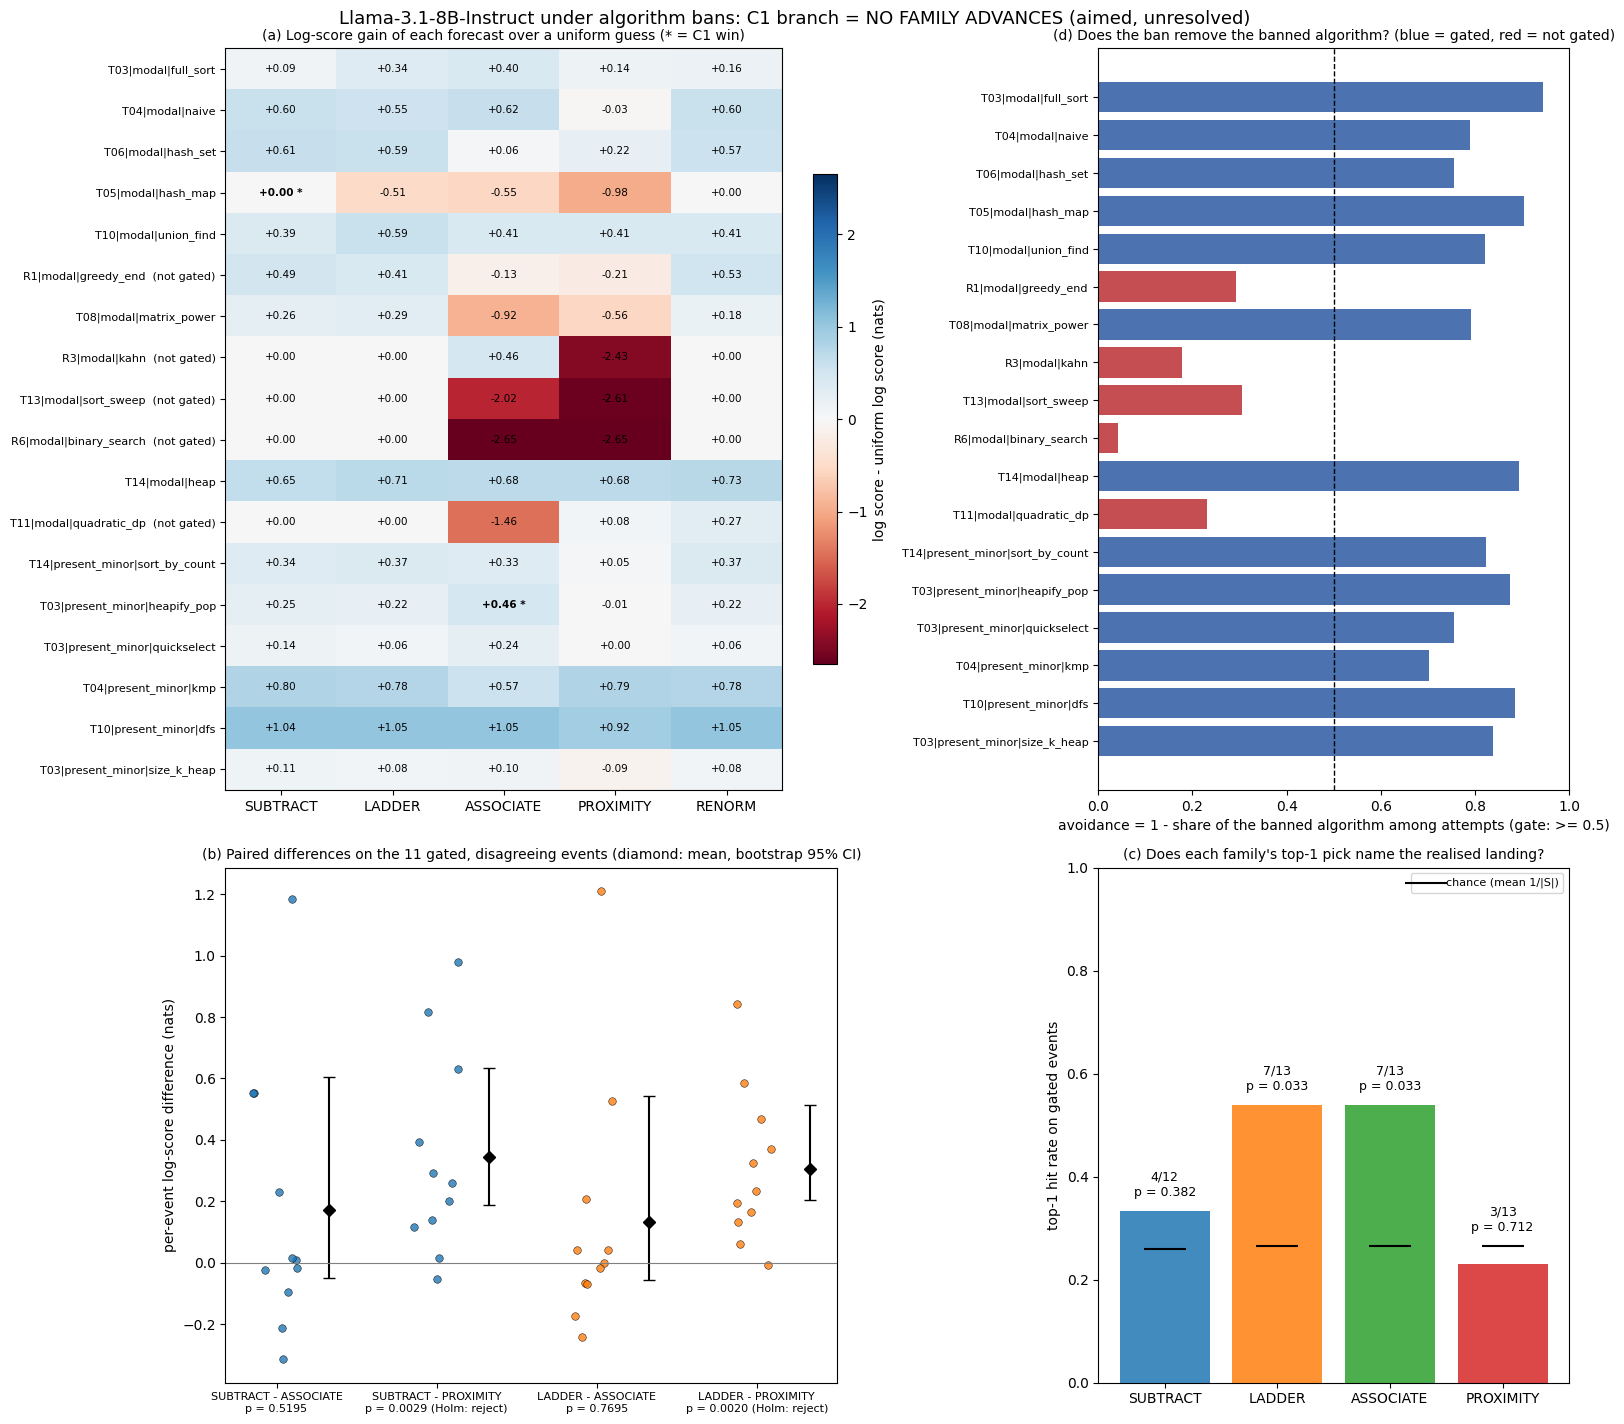

In [27]:
FAM_COL = {"SUBTRACT": "#1f77b4", "LADDER": "#ff7f0e", "ASSOCIATE": "#2ca02c", "PROXIMITY": "#d62728",
           "RENORM": "#7f7f7f"}
eids = [e["event_id"] for e in evs]
scs = [out["events"][eid]["scored"] for eid in eids]
cols = FAMILIES + ["RENORM"]

fig = plt.figure(figsize=(16, 0.36 * len(eids) + 8))
gs = fig.add_gridspec(2, 2, height_ratios=[max(0.36 * len(eids), 2.5), 4.5], width_ratios=[1.3, 1])
ax_a, ax_d = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
ax_b, ax_c = fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])

# (a) log-score gain of each forecast over the uniform forecast, per event
gain = np.array([[sc["logscore"][f] - sc["logscore"]["UNIFORM"] for f in cols] for sc in scs], dtype=float)
lim = (float(np.nanmax(np.abs(gain))) if np.isfinite(gain).any() else 1.0) or 1.0
im = ax_a.imshow(gain, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
ax_a.set_xticks(range(len(cols)), cols)
ax_a.set_yticks(range(len(eids)), [eid + ("" if sc["gate"]["gate_pass"] else "  (not gated)")
                                   for eid, sc in zip(eids, scs)], fontsize=8)
for i, sc in enumerate(scs):
    for j, f in enumerate(cols):
        if np.isfinite(gain[i, j]):
            ax_a.text(j, i, f"{gain[i, j]:+.2f}" + (" *" if sc["winner"] == f else ""), ha="center", va="center",
                      fontsize=7.5, fontweight="bold" if sc["winner"] == f else "normal")
fig.colorbar(im, ax=ax_a, fraction=0.04, label="log score - uniform log score (nats)")
ax_a.set_title("(a) Log-score gain of each forecast over a uniform guess (* = C1 win)", fontsize=10)

# (d) avoidance: did the ban remove the banned algorithm at all?
av = np.array([sc["gate"]["avoidance"] for sc in scs], dtype=float)
ax_d.barh(range(len(eids)), np.nan_to_num(av),
          color=["#4c72b0" if sc["gate"]["gate_pass"] else "#c44e52" for sc in scs])
ax_d.axvline(0.5, ls="--", color="k", lw=1)
ax_d.set_yticks(range(len(eids)), eids, fontsize=8)
ax_d.invert_yaxis()
ax_d.set_xlim(0, 1)
ax_d.set_xlabel("avoidance = 1 - share of the banned algorithm among attempts (gate: >= 0.5)")
ax_d.set_title("(d) Does the ban remove the banned algorithm? (blue = gated, red = not gated)", fontsize=10)

# (b) the paired per-event differences behind the four Wilcoxon tests
gd = [sc for sc in scs if sc["gate"]["gate_pass"] and sc["disagreeing"]]
wil = out["c1"]["wilcoxon"]
labels_b = []
for i, (a_, b_) in enumerate(PAIRS):
    d = np.array([sc["logscore"][a_] - sc["logscore"][b_] for sc in gd], dtype=float)
    ax_b.scatter(i + np.random.default_rng(i).uniform(-0.15, 0.15, len(d)), d, s=30, color=FAM_COL[a_],
                 edgecolor="k", linewidth=0.4, alpha=0.8)
    w = wil.get(f"{a_}-{b_}")
    if w:
        ax_b.errorbar(i + 0.33, w["mean_diff"], yerr=[[w["mean_diff"] - w["boot_ci"][0]], [w["boot_ci"][1] - w["mean_diff"]]],
                      fmt="D", color="k", ms=6, capsize=4)
        labels_b.append(f"{a_} - {b_}\np = {w['p']:.4f}" + (" (Holm: reject)" if w["reject"] else ""))
    else:
        labels_b.append(f"{a_} - {b_}")
ax_b.axhline(0, color="grey", lw=0.8)
ax_b.set_xticks(range(len(PAIRS)), labels_b, fontsize=8)
ax_b.set_ylabel("per-event log-score difference (nats)")
ax_b.set_title(f"(b) Paired differences on the {len(gd)} gated, disagreeing events (diamond: mean, bootstrap 95% CI)"
               + (f"\nWilcoxon not run: {wil['not_run']}" if "not_run" in wil else ""), fontsize=10)

# (c) top-1 hit rates on gated events against chance
hits = out["c1"]["top1_hits_gated"]
x = np.arange(len(FAMILIES))
rates = np.array([hits[f]["rate"] for f in FAMILIES], dtype=float)
ax_c.bar(x, np.nan_to_num(rates), color=[FAM_COL[f] for f in FAMILIES], alpha=0.85)
ax_c.scatter(x, [hits[f]["chance"] for f in FAMILIES], marker="_", s=900, color="k", zorder=3,
             label="chance (mean 1/|S|)")
for i, f in enumerate(FAMILIES):
    h = hits[f]
    ax_c.text(i, max(np.nan_to_num(rates[i]), np.nan_to_num(h["chance"])) + 0.03,
              f"{h['hits']}/{h['n']}" + (f"\np = {h['p_binom']:.3f}" if h["n"] else ""),
              ha="center", fontsize=9)
ax_c.set_xticks(x, FAMILIES)
ax_c.set_ylim(0, 1)
ax_c.set_ylabel("top-1 hit rate on gated events")
ax_c.legend(loc="upper right", fontsize=8)
ax_c.set_title("(c) Does each family's top-1 pick name the realised landing?", fontsize=10)

fig.suptitle(f"Llama-3.1-8B-Instruct under algorithm bans: C1 branch = {out['c1']['branch']}", fontsize=13)
fig.tight_layout()
plt.show()

### Figure 2: where the model went vs where each family said it would go

One panel per event:

* Grey bars are the observed landing under the ban: each surviving algorithm's share of the non-banned attempts.
* Coloured markers are each family's smoothed forecast q for the same bins, i.e. exactly the probabilities the log score is computed from.

A family that puts its mass where the grey bars are tall scores well.

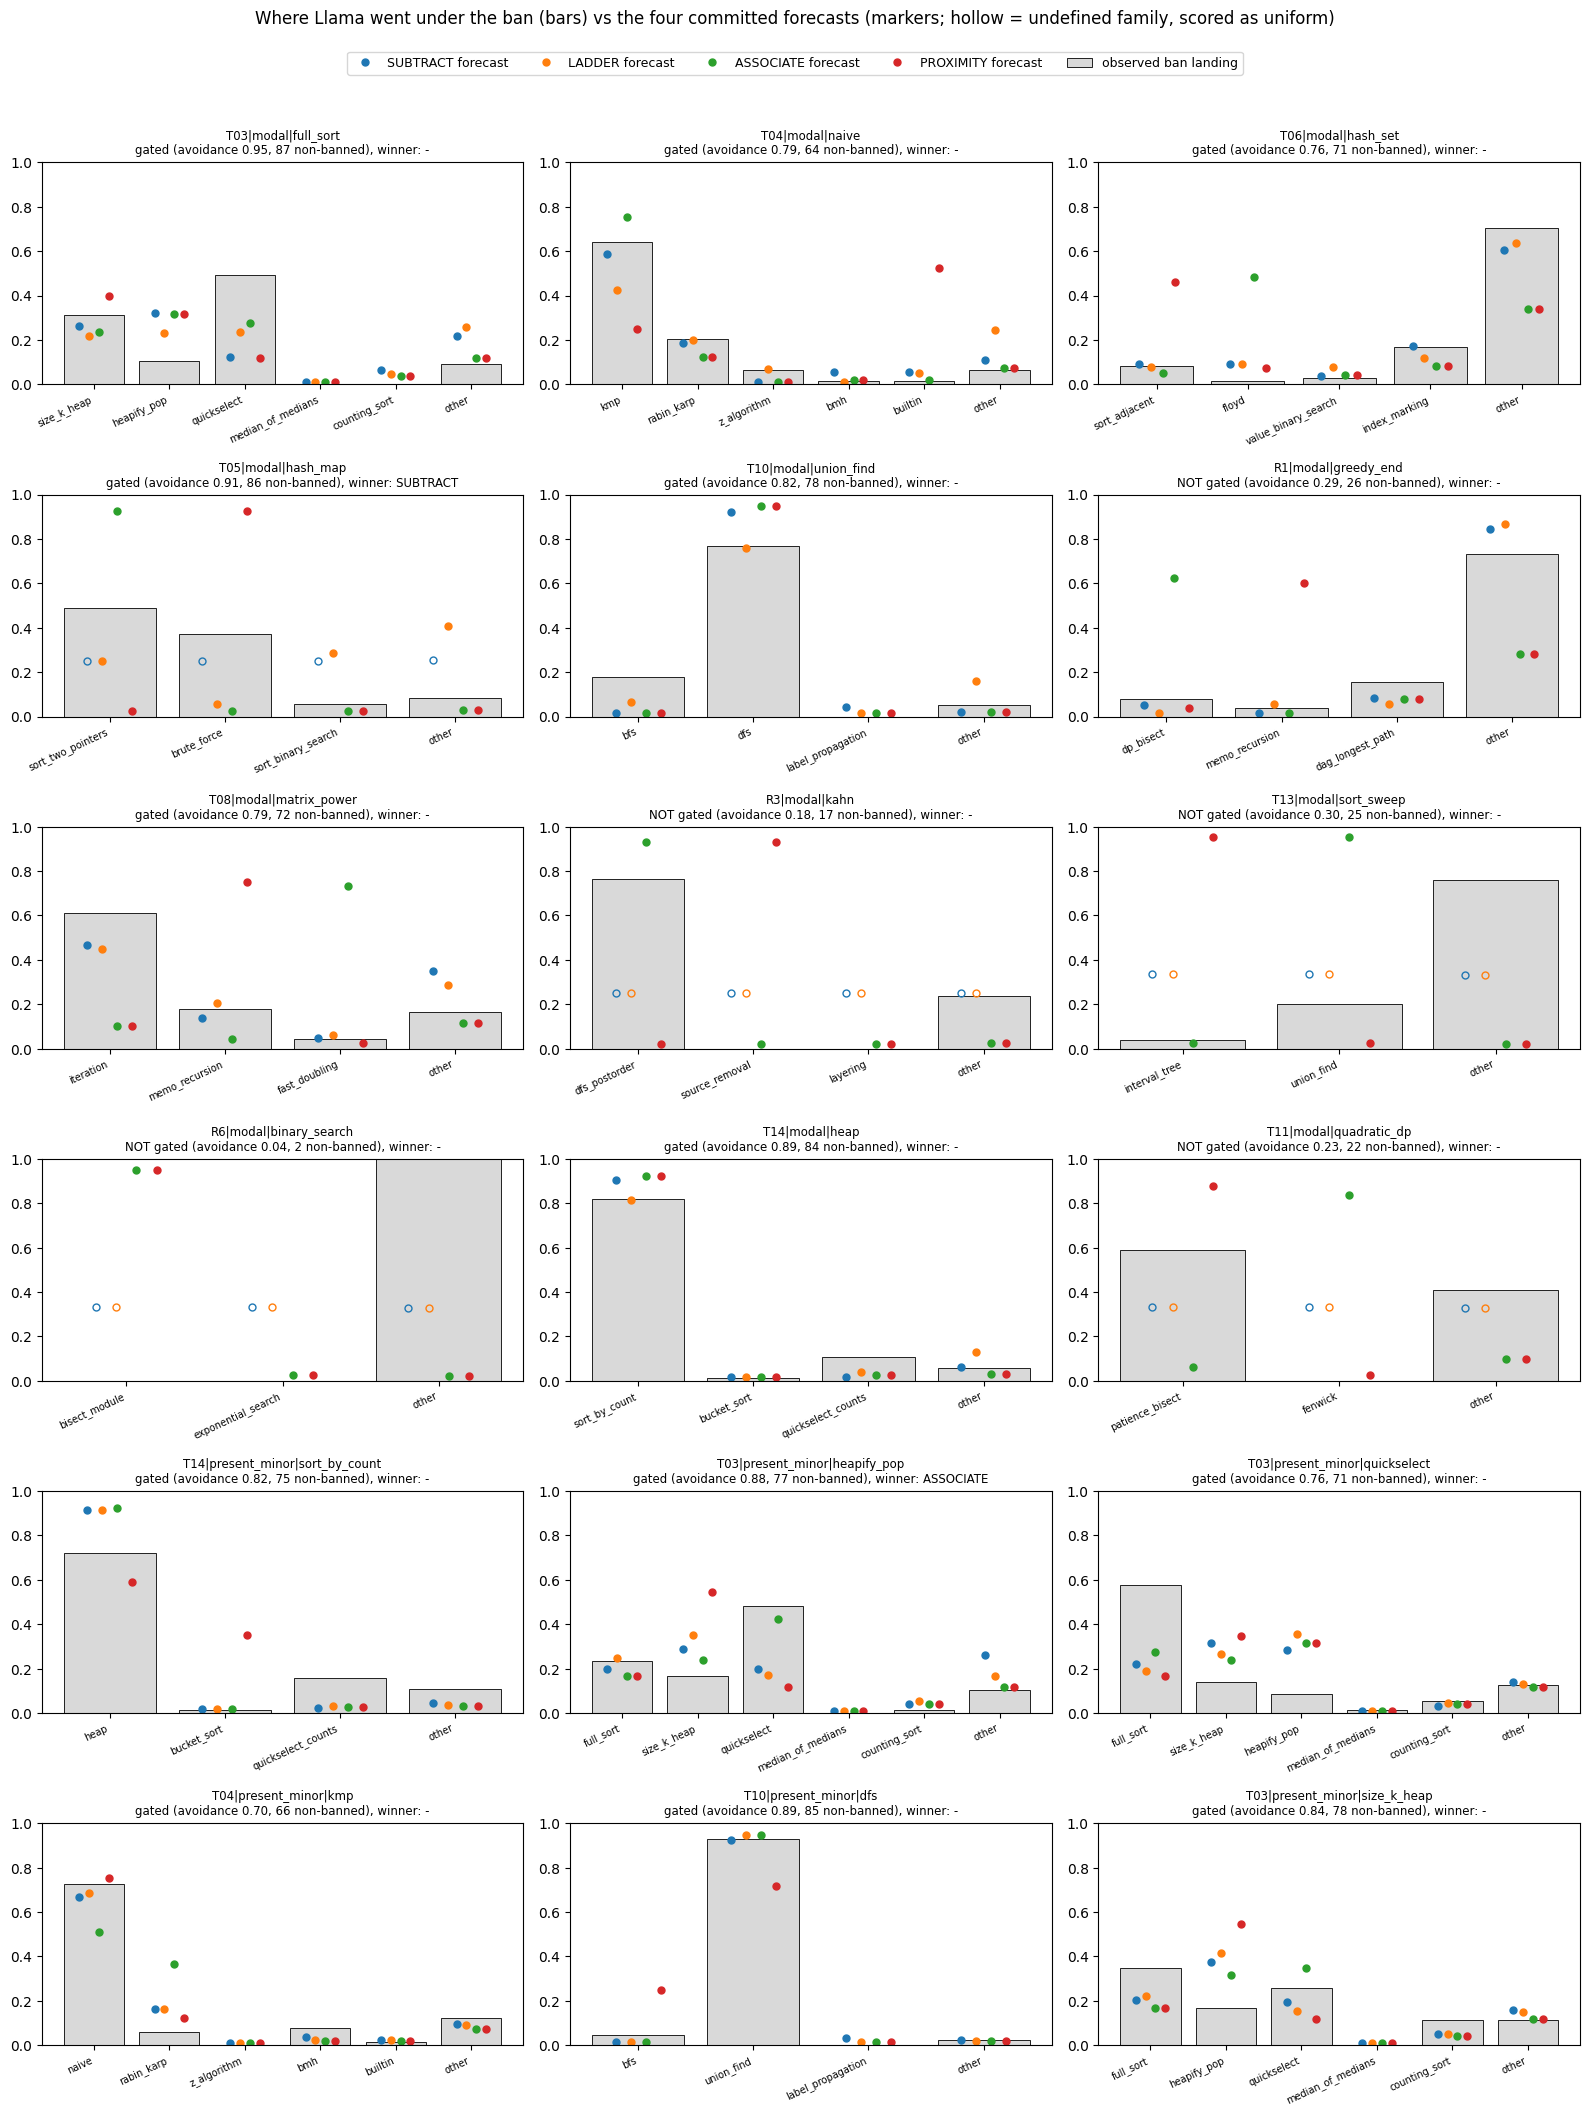

In [28]:
n = len(evs)
ncol = 3
nrow = math.ceil(n / ncol)
fig, axs = plt.subplots(nrow, ncol, figsize=(16, 3.4 * nrow), squeeze=False)
for k, e in enumerate(evs):
    ax = axs[k // ncol][k % ncol]
    fc, sc = fcs[e["event_id"]], out["events"][e["event_id"]]["scored"]
    S, bins = fc["S"], fc["bins"]
    xb = np.arange(len(bins))
    ax.bar(xb, [sc["landing"].get(b, 0.0) for b in bins], color="#d9d9d9", edgecolor="k", lw=0.6,
           label="observed ban landing" if k == 0 else None)
    for j, f in enumerate(FAMILIES):
        fam = fc["families"][f]
        q = smooth(fam["f"] if fam["defined"] else None, S)  # the probabilities the log score is computed from
        ax.plot(xb + (j - 1.5) * 0.13, [q[b] for b in bins], "o", color=FAM_COL[f], ms=5,
                mfc=FAM_COL[f] if fam["defined"] else "none", label=f"{f} forecast" if k == 0 else None)
    ax.set_xticks(xb, bins, rotation=25, ha="right", fontsize=7)
    ax.set_ylim(0, 1)
    g = sc["gate"]
    ax.set_title(f"{e['event_id']}\n{'gated' if g['gate_pass'] else 'NOT gated'} (avoidance {g['avoidance']:.2f}, "
                 f"{g['n_nonbanned']} non-banned), winner: {sc['winner'] or '-'}", fontsize=8.5)
for k in range(n, nrow * ncol):
    axs[k // ncol][k % ncol].axis("off")
fig.legend(loc="lower center", ncol=5, fontsize=9, bbox_to_anchor=(0.5, 1.0))
fig.suptitle("Where Llama went under the ban (bars) vs the four committed forecasts (markers; hollow = undefined "
             "family, scored as uniform)", y=1.035, fontsize=12)
fig.tight_layout()
plt.show()

## Takeaways

* **The forecasts were fixed before the bans.** All 18 forecasts rebuild exactly from the ban-free generations, and the committed file hashes to the entry made before the first ban sample.
* **A ban often fails to remove the default.** Five of the 12 modal defaults (R1, R3, T13, R6, T11) still make up 70–96 % of the attempts under an explicit ban (avoidance 0.04–0.30), so those events fail the gate.
* **The landing is partly predictable, but no family dominates.** On the 11 gated, disagreeing events, SUBTRACT and LADDER beat PROXIMITY in log score, yet only 2 events produce a ≥ 0.10-nat win, so no family advances: the branch is *NO FAMILY ADVANCES (aimed, unresolved)*. The landings are aimed rather than random: LADDER and ASSOCIATE name the realised top-1 landing on 7/13 gated events (chance ≈ 0.27, one-sided binomial p = 0.033).
* **The decision is fragile.** Scoring only correct programs, using the bf16-only decision set, or dropping template W4 each hands ASSOCIATE a third win, which turns the branch into SUBSTITUTION.

To run the full pipeline, use the experiment's own folder of the repository (`method.py`, `src/`, `restore.sh`). `restore.sh` recreates the environment, and also downloads the model weights when run with `DOWNLOAD_MODEL=1`. Then run `python method.py <sub-command>` in the order of the table at the top. The original run used one NVIDIA L4 (about 1.8 GPU-hours) and USD 0.48 of judge calls.